# Structure Harvester — Evanno Method (ΔK) Analysis + CLUMPP indfile

This notebook runs **structureHarvester** on a STRUCTURE results archive (`Results.zip`),  
plots the **Evanno ΔK criterion** (linear and log-scale), and generates a **CLUMPP-ready `indfile`**  
for any chosen K.

### Workflow
| Cell | Action |
|------|--------|
| 1 | Install structureHarvester (once per session) |
| 2 | ★ Set paths (edit before running) |
| 3 | Unzip results + run structureHarvester (`--evanno`) |
| 4 | Parse `evanno.txt` → linear ΔK plot |
| 5 | Same data → **log-scale ΔK plot** (reveals secondary peaks) |
| 6 | ★ Set target K → extract Q-matrices → write CLUMPP `indfile` |
| 7 | *(optional)* Print raw `summary.txt` |

---
> **Citations**  
> Earl & vonHoldt (2012) *STRUCTURE HARVESTER*. Conserv. Genet. Resour. 4(2) 359–361. DOI: 10.1007/s12686-011-9548-7  
> Jakobsson & Rosenberg (2007) *CLUMPP*. Bioinformatics 23: 1801–1806. DOI: 10.1093/bioinformatics/btm233


## structureHarvester installation

In [ ]:
# ── CELL 1 ─────────────────────────────────────────────────────────────────
# Install structureHarvester (downloads from GitHub once per session)
# ───────────────────────────────────────────────────────────────────────────
import os, subprocess, sys

HARVESTER_DIR = "/content/structureHarvester-master"

if not os.path.isdir(HARVESTER_DIR):
    print("Downloading structureHarvester …")
    subprocess.run(
        ["wget", "-q", "https://github.com/dentearl/structureHarvester/archive/master.zip",
         "-O", "/content/harvester_master.zip"],
        check=True
    )
    subprocess.run(
        ["unzip", "-q", "-o", "/content/harvester_master.zip", "-d", "/content"],
        check=True
    )
    print("structureHarvester installed.")
else:
    print("structureHarvester already present — skipping download.")

if HARVESTER_DIR not in sys.path:
    sys.path.insert(0, HARVESTER_DIR)

print("Done.")

structureHarvester already present — skipping download.
Done.


## ★ USER SETTINGS [configure/check every time]

In [ ]:
# ── CELL 2 ─────────────────────────────────────────────────────────────────
# ★ USER SETTINGS — edit these paths before running
# ───────────────────────────────────────────────────────────────────────────

# Path to your STRUCTURE results zip (upload it first via the Files panel)
RESULTS_ZIP = "/content/structure_results.zip"

# Where to unpack the _f files
RESULTS_DIR = "/content/structure_results"

# Where structureHarvester writes summary.txt / evanno.txt
OUTPUT_DIR  = "/content/harvester_output"

print(f"Results ZIP : {RESULTS_ZIP}")
print(f"Results dir : {RESULTS_DIR}")
print(f"Output dir  : {OUTPUT_DIR}")

Results ZIP : /content/structure_results.zip
Results dir : /content/structure_results
Output dir  : /content/harvester_output


## Unzip STRUCTURE results and run structureHarvester

In [ ]:
# ── CELL 3 ─────────────────────────────────────────────────────────────────
# Unzip STRUCTURE results and run structureHarvester with --evanno flag
# ───────────────────────────────────────────────────────────────────────────
import os, subprocess

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR,  exist_ok=True)

# 1. Unzip STRUCTURE results (-o = overwrite silently)
print("Extracting Results.zip …")
r = subprocess.run(
    ["unzip", "-o", RESULTS_ZIP, "-d", RESULTS_DIR],
    capture_output=True, text=True
)
if r.returncode != 0:
    raise RuntimeError(f"unzip failed:\n{r.stderr}")

f_files = [f for f in os.listdir(RESULTS_DIR) if f.endswith("_f")]
print(f"Found {len(f_files)} _f files.")

# 2. Run structureHarvester with the --evanno flag
print("\nRunning structureHarvester …")
SCRIPT = "/content/structureHarvester-master/structureHarvester.py"
r = subprocess.run(
    ["python", SCRIPT,
     "--dir", RESULTS_DIR,
     "--out", OUTPUT_DIR,
     "--evanno"],
    capture_output=True, text=True
)
if r.stdout: print(r.stdout)
if r.stderr: print("STDERR:", r.stderr)

print("\nOutput files:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(" ", f)

Extracting Results.zip …
Found 220 _f files.

Running structureHarvester …

Output files:
  .ipynb_checkpoints
  deltaK_linear.png
  deltaK_log.png
  evanno.txt
  summary.txt


## ΔK plot [linear]. Structure Harvester

 K  Reps  Mean_LnP  Stdev_LnP    LnPK   LnPPK    Delta_K
 1    20 -5073.065     0.8324     NaN     NaN        NaN
 2    20 -4724.990     1.0809 348.075 204.030 188.761712
 3    20 -4580.945     7.0173 144.045   4.215   0.600658
 4    20 -4441.115     2.2441 139.830  84.030  37.444505
 5    20 -4385.315     3.7966  55.800   9.055   2.385045
 6    20 -4320.460     1.7703  64.855  44.870  25.345408
 7    20 -4300.475     5.7126  19.985  13.370   2.340449
 8    20 -4267.120    10.9862  33.355  11.465   1.043583
 9    20 -4245.230     8.9468  21.890   7.290   0.814816
10    20 -4230.630    81.7874  14.600  64.370   0.787041
11    20 -4280.400   101.3421 -49.770     NaN        NaN

Optimal K by Evanno ΔK method: K = 2


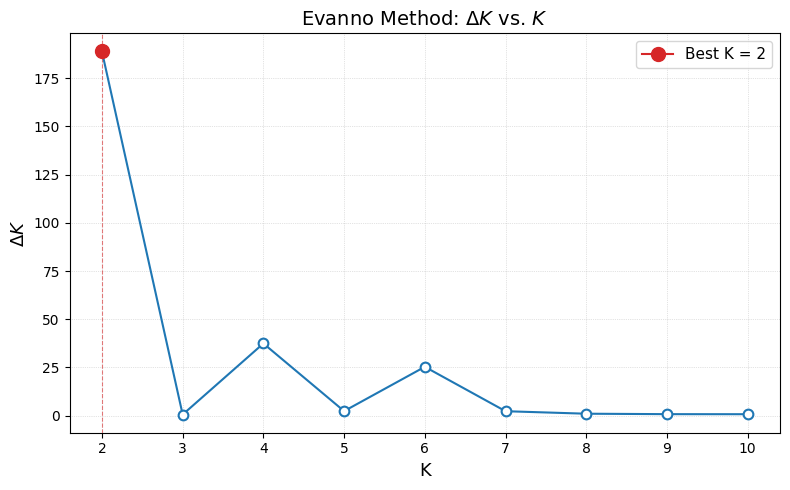

Saved: /content/harvester_output/deltaK_linear.png


In [ ]:
# ── CELL 4 ─────────────────────────────────────────────────────────────────
# Parse evanno.txt and plot ΔK  (linear y-axis)
# ───────────────────────────────────────────────────────────────────────────
import os, re
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

EVANNO_FILE = os.path.join(OUTPUT_DIR, "evanno.txt")

# ── Parse evanno.txt ───────────────────────────────────────────────────────
# Columns: K  Reps  Mean_LnP  Stdev_LnP  Ln'(K)  |Ln''(K)|  Delta_K
# NA appears for K=1 (no Ln'(K)) and K_max (no Delta_K)

rows = []
with open(EVANNO_FILE) as fh:
    for line in fh:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        parts = line.split()
        if len(parts) < 7:
            continue
        try:
            k         = int(parts[0])
            reps      = int(parts[1])
            mean_lnp  = float(parts[2])
            stdev_lnp = float(parts[3])
            lnpk      = None if parts[4] == "NA" else float(parts[4])
            lnppk     = None if parts[5] == "NA" else float(parts[5])
            delta_k   = None if parts[6] == "NA" else float(parts[6])
            rows.append(dict(K=k, Reps=reps,
                             Mean_LnP=mean_lnp, Stdev_LnP=stdev_lnp,
                             LnPK=lnpk, LnPPK=lnppk, Delta_K=delta_k))
        except ValueError:
            continue

df_evanno = pd.DataFrame(rows).sort_values("K").reset_index(drop=True)
print(df_evanno.to_string(index=False))

# ── Identify best K ────────────────────────────────────────────────────────
df_dk = df_evanno.dropna(subset=["Delta_K"])
best_k = int(df_dk.loc[df_dk["Delta_K"].idxmax(), "K"])
print(f"\nOptimal K by Evanno ΔK method: K = {best_k}")

# ── Plot (linear) ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df_dk["K"], df_dk["Delta_K"],
    color="#1f77b4", linewidth=1.5,
    marker="o", markersize=7,
    markerfacecolor="white", markeredgewidth=1.5, zorder=3
)
peak_row = df_dk[df_dk["K"] == best_k].iloc[0]
ax.plot(peak_row["K"], peak_row["Delta_K"],
        marker="o", markersize=10, color="#d62728", zorder=4,
        label=f"Best K = {best_k}")
ax.axvline(best_k, color="#d62728", linestyle="--", linewidth=0.8, alpha=0.6)

ax.set_xlabel("K", fontsize=13)
ax.set_ylabel(r"$\Delta K$", fontsize=13)
ax.set_title(r"Evanno Method: $\Delta K$ vs. $K$", fontsize=14)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.7)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "deltaK_linear.png"), dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", os.path.join(OUTPUT_DIR, "deltaK_linear.png"))

## ΔK plot [log-scale]. Structure Harvester

NameError: name 'df_dk' is not defined

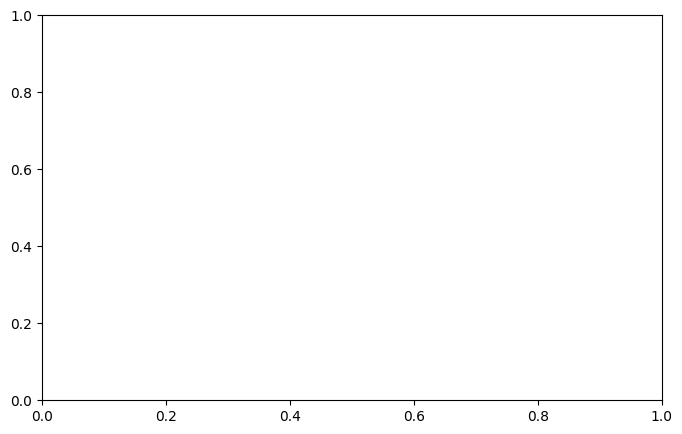

In [ ]:
# ── CELL 5 v2 ────────────────────────────────────────────────────────────────
# Same ΔK data — LOG-SCALE y-axis.
# v2: cap the number of highlighted secondary peaks (keep the strongest N by ΔK)
#     so extra local maxima at high K (e.g. K=9/K=10 noise) aren't over-flagged.
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np

# df_dk is already available from Cell 4; re-run Cell 4 first if needed.

MAX_SECONDARY = 2        # ← max number of secondary peaks to highlight

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df_dk["K"], df_dk["Delta_K"],
    color="#1f77b4", linewidth=1.5,
    marker="o", markersize=7,
    markerfacecolor="white", markeredgewidth=1.5, zorder=3
)

# Annotate every K with its ΔK value
for _, row in df_dk.iterrows():
    ax.annotate(
        f"{row['Delta_K']:.2f}",
        xy=(row["K"], row["Delta_K"]),
        xytext=(4, 4), textcoords="offset points",
        fontsize=9, color="#333333"
    )

# Highlight the global peak
peak_row = df_dk[df_dk["K"] == best_k].iloc[0]
ax.plot(peak_row["K"], peak_row["Delta_K"],
        marker="o", markersize=10, color="#d62728", zorder=4,
        label=f"Best K = {best_k} (ΔK = {peak_row['Delta_K']:.1f})")
ax.axvline(best_k, color="#d62728", linestyle="--", linewidth=0.8, alpha=0.6)

# Secondary peaks: find ALL local maxima (excluding the global peak),
# then keep only the strongest MAX_SECONDARY by ΔK.
dk_vals = df_dk["Delta_K"].values
k_vals  = df_dk["K"].values
secondary = [
    (k_vals[i], dk_vals[i])
    for i in range(1, len(dk_vals) - 1)
    if dk_vals[i] > dk_vals[i-1] and dk_vals[i] > dk_vals[i+1] and k_vals[i] != best_k
]
secondary = sorted(secondary, key=lambda t: t[1], reverse=True)[:MAX_SECONDARY]  # top-N by ΔK
secondary = sorted(secondary, key=lambda t: t[0])                                # then by K for legend

for k_sec, dk_sec in secondary:
    ax.plot(k_sec, dk_sec,
            marker="^", markersize=9, color="#ff7f0e", zorder=4,
            label=f"Secondary peak K = {int(k_sec)} (ΔK = {dk_sec:.2f})")

ax.set_yscale("log")
ax.set_xlabel("K", fontsize=13)
ax.set_ylabel(r"$\Delta K$  (log scale)", fontsize=13)
ax.set_title(r"Evanno Method: $\Delta K$ vs. $K$  [log scale]", fontsize=14)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(True, which="both", linestyle=":", linewidth=0.5, alpha=0.7)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "deltaK_log.png"), dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", os.path.join(OUTPUT_DIR, "deltaK_log.png"))

## CLUMPP indfile 🍒 [input file] generator for a chosen K
### UKR_CherryID project "breeding germplasm pseudopopulation vesion" 🍒

In [ ]:
# ── CELL 6 v5 — Generate CLUMPP indfile for a chosen K (project metadata.txt) ──
# Changes vs v4:
#   • Reads the current metadata.txt (N_n, sample_name, aprior_name,
#     posterior_name, duplicate_of, status, origin, S_genotype, PavCNR12).
#     There is NO integer pop-code column any more, so the CLUMPP pop column is
#     DERIVED from a categorical field (POP_FIELD, default "status"); an integer
#     legend is auto-built and printed. NB: for DATATYPE 0 the pop column is a
#     pass-through (used only for downstream grouping), not for alignment.
#   • Maps metadata → STRUCTURE output BY SAMPLE NAME, not by serial. Essential:
#     the clone-corrected run is renumbered 1..90 and no longer matches
#     metadata N_n (1..94, incl. the 4 duplicates), so serial lookup is wrong.
#   • Header-safe; tolerates _f runs with or without a pop column.
#   • Also writes a sidecar sample-key for annotating the final plot.
#   • Does NOT generate a paramfile (maintain your working one manually).
# ─────────────────────────────────────────────────────────────────────────────
import os, re, glob

# ★ Set target K and the metadata field used as the CLUMPP "pop" column
TARGET_K  = 7
POP_FIELD = "status"        # e.g. "status" or "origin" — any metadata column

# ── Paths ─────────────────────────────────────────────────────────────────────
METAFILE    = "/content/metadata.txt"
RESULTS_DIR = "/content/structure_results"    # folder with the _f files
OUTPUT_DIR  = "/content/harvester_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

INDFILE = os.path.join(OUTPUT_DIR, f"CherryID_K{TARGET_K}.indfile")
KEYFILE = os.path.join(OUTPUT_DIR, f"CherryID_K{TARGET_K}.samplekey.tsv")

# ── Patterns ──────────────────────────────────────────────────────────────────
pop_pat   = re.compile(r'^\s*(\d+)\s+populations assumed', re.MULTILINE)
anc_start = re.compile(r'Inferred ancestry of individuals:')
# index  label  (miss)  [optional pop]  :  q-values
line_pat  = re.compile(r'^\s*(\d+)\s+(\S+)\s+\(\s*(\d+)\s*\)\s+(?:(\d+)\s+)?:\s+(.+)$')

# ── 1. Load metadata.txt, keyed by sample_name ───────────────────────────────
meta, header = {}, None
with open(METAFILE, encoding="utf-8") as fh:
    for raw in fh:
        line = raw.rstrip("\r\n")
        if not line.strip():
            continue
        parts = line.split("\t")
        if header is None:                       # first non-empty row = header
            header = [h.strip() for h in parts]
            continue
        row = {header[i]: (parts[i].strip() if i < len(parts) else "")
               for i in range(len(header))}
        name = row.get("sample_name", "").strip()
        if name:
            meta[name] = row

if not meta:
    raise ValueError("No records parsed from metadata — check file path / tabs.")
if POP_FIELD not in header:
    raise KeyError(f"POP_FIELD '{POP_FIELD}' not in columns: {header}")
print(f"Loaded metadata for {len(meta)} samples.  Columns: {header}")

# ── 2. Build integer pop codes from POP_FIELD (NA sorted last) ───────────────
def norm(v):
    v = (v or "").strip()
    return v if v else "NA"

cats = sorted({norm(r[POP_FIELD]) for r in meta.values()})
cats = [c for c in cats if c != "NA"] + (["NA"] if "NA" in cats else [])
pop_code    = {c: i + 1 for i, c in enumerate(cats)}
name_to_pop = {n: pop_code[norm(r[POP_FIELD])] for n, r in meta.items()}
print(f"\nPop codes from '{POP_FIELD}':")
for c in cats:
    print(f"  {pop_code[c]:>2}  {c}")

# ── 3. Locate _f files for TARGET_K (picks up K11 etc. automatically) ────────
all_f = sorted(glob.glob(os.path.join(RESULTS_DIR, "*_f")))
if not all_f:
    raise FileNotFoundError(f"No _f files in {RESULTS_DIR}")

def k_of(fp):
    with open(fp, errors="replace") as f:
        m = pop_pat.search(f.read())
    return int(m.group(1)) if m else None

target_files = []
for fp in all_f:
    if k_of(fp) == TARGET_K:
        rn = re.search(r'rep(\d+)_f$|_(\d+)_f$', os.path.basename(fp))
        run = int(next((g for g in rn.groups() if g), 0)) if rn else 0
        target_files.append((run, fp))
target_files.sort()

if not target_files:
    available = sorted({k for fp in all_f if (k := k_of(fp))})
    raise ValueError(f"No _f files for K={TARGET_K}. Available K: {available}")
print(f"\nFound {len(target_files)} runs for K={TARGET_K}.")

# ── 4. Extract the ancestry block from one _f file ───────────────────────────
def extract_ancestry_lines(fp):
    out, in_sec, skip = [], False, False
    with open(fp, errors="replace") as f:
        for line in f:
            if not in_sec:
                if anc_start.search(line):
                    in_sec, skip = True, True
                continue
            if skip:
                if line.strip():
                    skip = False
                continue
            if not line.strip():
                break
            out.append(line)
    if not out:
        raise ValueError(f"No ancestry data in {os.path.basename(fp)}")
    return out

# ── 5. Reformat one line to CLUMPP indfile format ────────────────────────────
#   col1 = col2 = STRUCTURE serial (int, stable across runs)
#   col3 = (miss)   col4 = pop code (looked up BY NAME)   col5 = q verbatim
unmatched = set()
def reformat_line(raw):
    m = line_pat.match(raw)
    if not m:
        return raw.rstrip("\r\n") + "\r\n"
    serial, label, miss = int(m.group(1)), m.group(2), m.group(3).strip()
    q_vals = " ".join(f"{float(v):.3f}" for v in m.group(5).split())
    if label in name_to_pop:
        pop = name_to_pop[label]
    else:
        unmatched.add(label)
        pop = 0
    return f"{serial:>3}  {serial:>3} ({miss}) {pop} :  {q_vals}\r\n"

# ── 6. Write indfile (R blocks of C individuals, blank line between) ──────────
n_runs, n_ind = len(target_files), None
with open(INDFILE, "w", newline="") as out:
    for i, (run, fp) in enumerate(target_files):
        block = extract_ancestry_lines(fp)
        if n_ind is None:
            n_ind = sum(1 for l in block if line_pat.match(l))
        for l in block:
            out.write(reformat_line(l))
        if i < n_runs - 1:
            out.write("\r\n")

# ── 7. Sidecar sample key (serial → names/status/origin/S) for plotting ──────
first_block = extract_ancestry_lines(target_files[0][1])
with open(KEYFILE, "w", newline="") as kf:
    kf.write("serial\tsample_name\tposterior_name\tstatus\torigin\tS_genotype\tpop_code\n")
    for l in first_block:
        m = line_pat.match(l)
        if not m:
            continue
        serial, label = m.group(1), m.group(2)
        r = meta.get(label, {})
        kf.write("\t".join([serial, label, r.get("posterior_name", ""),
                            r.get("status", ""), r.get("origin", ""),
                            r.get("S_genotype", ""),
                            str(name_to_pop.get(label, 0))]) + "\n")

# ── 8. Report ────────────────────────────────────────────────────────────────
print(f"\nindfile : {INDFILE}")
print(f"key     : {KEYFILE}")
print(f"  C (individuals) = {n_ind}")
print(f"  K (clusters)    = {TARGET_K}")
print(f"  R (runs)        = {n_runs}")
if unmatched:
    print(f"\n⚠  {len(unmatched)} labels not in metadata (pop set to 0): {sorted(unmatched)}")
else:
    print("\nAll STRUCTURE labels matched metadata by name.  ✓")

print(f"""
paramfile values for K={TARGET_K}  (edit your working paramfile — do not regenerate):
  DATATYPE 0 | INDFILE CherryID_K{TARGET_K}.indfile | OUTFILE CherryID_K{TARGET_K}.outfile | MISCFILE CherryID_K{TARGET_K}.miscfile
  K {TARGET_K} | C {n_ind} | R {n_runs} | M 2 (LargeKGreedy) | W 0 (ignored, DATATYPE 0) | S 2 (G')
  GREEDY_OPTION 2 | REPEATS 1000 | PRINT_PERMUTED_DATA 1 | PERMUTED_DATAFILE CherryID_K{TARGET_K}.perm | ORDER_BY_RUN 1
""")

print("First 3 indfile lines:")
with open(INDFILE, newline="") as fh:
    for i, l in enumerate(fh):
        if i >= 3:
            break
        print("  ", repr(l))

## 🍒STRUCTURE *or* DAPC bar plot
### UKR_CherryID project "breeding germplasm pseudopopulation vesion" 🍒

STRUCTURE parsed: 90 individuals, K=2
  Modern cultivars: 49
  Early selection cultivars & Landraces: 32
  Wild: 9


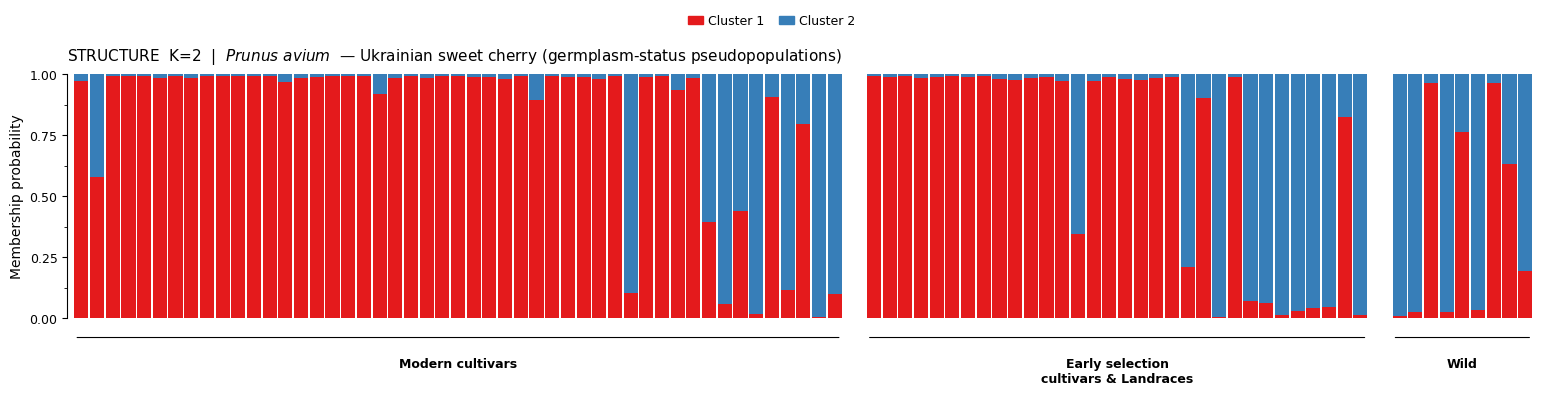

NameError: name 'OUT_SVG' is not defined

In [ ]:
# ── CELL 7 v7 — DAPC (or STRUCTURE) membership bar plot ───────────────────────
#   CHERRY germplasm-status PSEUDOPOPULATIONS (domesticated vs wild).
#
# NOTE ON "POPULATIONS": unlike v6 (real EAB geographic/wild demes), the groups
# here are germplasm CATEGORIES, not panmictic populations. DAPC clustering was
# UNSUPERVISED; these bands are a display grouping only, used to read how the
# de-novo clusters distribute across breeding status.
#
# Grouping (from the `status` field / DAPC pop_name column):
#   "Modern cultivars"                       = Modern cultivar  +  NA
#        (NA = unresolved-identity accessions; folded into Modern cultivars,
#         consistent with where they land in the DAPC Q-scores)
#   "Early selection cultivars & Landraces"  = Early selection cultivar + Landrace
#   "Wild"                                   = Wild
#
# Accepts:
#   • DAPC posterior CSV/TXT (sample_name, pop_name, assigned_cluster, Cluster_1…K)
#         → pop_name already carries `status`; no metadata join needed
#   • STRUCTURE CLUMPP outfile → serial (N_n) mapped to `status` via metadata
# K is auto-detected. ★ Edit only the two paths.
# ─────────────────────────────────────────────────────────────────────────────
import re, os, csv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import MultipleLocator
# from google.colab import files

# ── ★ EDIT THESE TWO PATHS ────────────────────────────────────────────────────
#INPUT_FILE = "/content/DAPC_K3_Qscores_ed.csv"   # DAPC csv/txt  OR  STRUCTURE outfile
INPUT_FILE = "/content/CherryID_K2.outfile"   # DAPC csv/txt  OR  STRUCTURE outfile
METAFILE   = "/content/metadata.txt"          # only needed for STRUCTURE mode

# ── Germplasm-status → display pseudopopulation ───────────────────────────────
STATUS_TO_GROUP = {
    "Modern cultivar":          "Modern cultivars",
    "NA":                       "Modern cultivars",                        # collapsed
    "Early selection cultivar": "Early selection cultivars & Landraces",
    "Landrace":                 "Early selection cultivars & Landraces",
    "Wild":                     "Wild",
}
GROUP_ORDER = ["Modern cultivars", "Early selection cultivars & Landraces", "Wild"]
GROUP_LABEL = {                              # bracket labels (wrap the long one)
    "Modern cultivars": "Modern cultivars",
    "Early selection cultivars & Landraces": "Early selection\ncultivars & Landraces",
    "Wild": "Wild",
}

# Cluster colours — match the R DAPC figures (adegenet Set1 / cluster_cols)
ALL_COLORS = ["#E41A1C", "#377EB8", "#4DAF4A", "#984EA3",
              "#FF7F00", "#A65628", "#F781BF", "#999999"]

# ═══════════════════════════════════════════════════════════════════════════════
# 1. DETECT INPUT TYPE + DELIMITER, PARSE Q-MATRIX
# ═══════════════════════════════════════════════════════════════════════════════
with open(INPUT_FILE) as fh:
    first = fh.readline()
delim   = "\t" if "\t" in first else ","
is_dapc = ("Cluster_1" in first) or ("sample_name" in first)

records  = []          # each: dict(name, group, q=[...], sort)
unmapped = set()

if is_dapc:
    source_label = "DAPC"
    with open(INPUT_FILE, newline="") as fh:
        reader = csv.DictReader(fh, delimiter=delim)
        clust_cols = [c for c in reader.fieldnames if c.startswith("Cluster_")]
        K = len(clust_cols)
        for i, row in enumerate(reader):
            status = (row.get("pop_name") or "").strip()
            grp    = STATUS_TO_GROUP.get(status)
            if grp is None:
                unmapped.add(status); continue
            q = [float(row[c]) for c in clust_cols]
            records.append(dict(name=row["sample_name"].strip(),
                                group=grp, q=q, sort=i))
    print(f"DAPC parsed: {len(records)} individuals, K={K}")

else:
    source_label = "STRUCTURE"
    # metadata: N_n (col 0) → status (col 5)
    serial_status = {}
    with open(METAFILE) as fh:
        for line in fh:
            line = line.rstrip("\n")
            if not line or line.startswith("N_n"):
                continue
            p = line.split("\t")
            if len(p) < 6:
                continue
            serial_status[int(p[0])] = p[5].strip()
    line_pat = re.compile(r'^\s*(\d+)\s+\d+\s+\(\s*\d+\s*\)\s+\d+\s*:\s+([\d. ]+)')
    with open(INPUT_FILE) as fh:
        for line in fh:
            m = line_pat.match(line)
            if not m:
                continue
            serial = int(m.group(1))
            q      = [float(v) for v in m.group(2).split()]
            status = serial_status.get(serial)
            grp    = STATUS_TO_GROUP.get(status)
            if grp is None:
                unmapped.add(f"serial {serial} (status={status!r})"); continue
            records.append(dict(name=str(serial), group=grp, q=q, sort=serial))
    K = len(records[0]["q"]) if records else 0
    print(f"STRUCTURE parsed: {len(records)} individuals, K={K}")

if unmapped:
    raise ValueError(f"Unmapped status/serial values (fix STATUS_TO_GROUP "
                     f"or metadata): {sorted(unmapped)}")
assert records, "No individuals parsed — check INPUT_FILE / METAFILE."
assert K <= len(ALL_COLORS), f"K={K} exceeds palette ({len(ALL_COLORS)})."
CLUSTER_COLORS = ALL_COLORS[:K]

# ═══════════════════════════════════════════════════════════════════════════════
# 2. ORDER INDIVIDUALS BY GROUP (within group: input / serial order)
# ═══════════════════════════════════════════════════════════════════════════════
ordered = []
for g in GROUP_ORDER:
    recs_g = sorted((r for r in records if r["group"] == g), key=lambda r: r["sort"])
    if not recs_g:
        print(f"WARNING: no individuals in group '{g}'")
        continue
    print(f"  {g}: {len(recs_g)}")
    ordered.extend(recs_g)

Q               = np.array([r["q"] for r in ordered])
groups_ordered  = [r["group"] for r in ordered]
N               = len(ordered)
groups_present  = [g for g in GROUP_ORDER if g in groups_ordered]

# ═══════════════════════════════════════════════════════════════════════════════
# 3. X-POSITIONS WITH INTER-GROUP GAPS
# ═══════════════════════════════════════════════════════════════════════════════
GAP, BAR_W = 1.5, 0.9
x_positions = np.zeros(N, dtype=float)
cursor = idx = 0
for g in groups_present:
    n = groups_ordered.count(g)
    for j in range(n):
        x_positions[idx + j] = cursor + j
    cursor += n + GAP
    idx    += n

# ═══════════════════════════════════════════════════════════════════════════════
# 4. PLOT
# ═══════════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(16, 4.2))
fig.subplots_adjust(top=0.82, bottom=0.24, left=0.06, right=0.98)

bottoms = np.zeros(N)
for k in range(K):
    ax.bar(x_positions, Q[:, k], bottom=bottoms,
           width=BAR_W, color=CLUSTER_COLORS[k], linewidth=0)
    bottoms += Q[:, k]

# Group brackets + labels
idx = 0
for g in groups_present:
    n = groups_ordered.count(g)
    x_left  = x_positions[idx] - BAR_W / 2
    x_right = x_positions[idx + n - 1] + BAR_W / 2
    mid     = (x_left + x_right) / 2
    idx    += n
    ax.annotate("", xy=(x_right, -0.08), xytext=(x_left, -0.08),
                xycoords=("data", "axes fraction"),
                textcoords=("data", "axes fraction"),
                annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color="black", lw=0.8))
    ax.text(mid, -0.16, GROUP_LABEL[g], ha="center", va="top",
            transform=ax.get_xaxis_transform(),
            fontsize=9, fontweight="bold", color="black", clip_on=False)

# Axes
ax.set_xlim(x_positions[0] - BAR_W, x_positions[-1] + BAR_W)
ax.set_ylim(0, 1)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.yaxis.set_minor_locator(MultipleLocator(0.125))
ax.set_ylabel("Membership probability", fontsize=10)
ax.set_xticks([])
ax.tick_params(axis="y", labelsize=9)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.spines["left"].set_linewidth(0.8)

# Legend above plot
patches = [mpatches.Patch(color=CLUSTER_COLORS[k], label=f"Cluster {k+1}")
           for k in range(K)]
fig.legend(handles=patches, loc="upper center", bbox_to_anchor=(0.5, 0.99),
           ncol=K, frameon=False, fontsize=9, handlelength=1.2,
           handletextpad=0.4, columnspacing=1.2)

# Title
k_in_fname = re.search(r'[Kk](\d+)', os.path.basename(INPUT_FILE))
k_label    = f"K={k_in_fname.group(1)}" if k_in_fname else f"K={K}"
ax.set_title(
    f"{source_label}  {k_label}  |  $Prunus$ $avium$  — Ukrainian sweet cherry "
    f"(germplasm-status pseudopopulations)",
    fontsize=11, pad=10, loc="left")

# ═══════════════════════════════════════════════════════════════════════════════
# 5. SAVE + DOWNLOAD
# ═══════════════════════════════════════════════════════════════════════════════
base    = os.path.splitext(os.path.basename(INPUT_FILE))[0]
OUT_PNG = f"{base}_barplot.png"
#OUT_SVG = f"{base}_barplot.svg"
fig.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
#fig.savefig(OUT_SVG, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_PNG}  |  {OUT_SVG}")
# files.download(OUT_PNG); files.download(OUT_SVG)

## 🍒STRUCTURE *or* DAPC bar plot
### UKR_CherryID project "breeding germplasm pseudopopulation vesion" 🍒
### ONE panel, TWO-TIER grouping

Metadata: 94 accessions.
Serial map from metadata minus EXCLUDED_NN=[24, 26, 52, 65]: 90 serials.
STRUCTURE parsed: 90 individuals, K=7
Ordering: reusing panel_order.txt (90 accessions).
   Modern cultivars                       Ukrainian      n=39
   Modern cultivars                       non-Ukrainian  n=9
   Early selection cultivars & Landraces  Ukrainian      n=25
   Early selection cultivars & Landraces  non-Ukrainian  n=8
   Wild                                   None           n=9


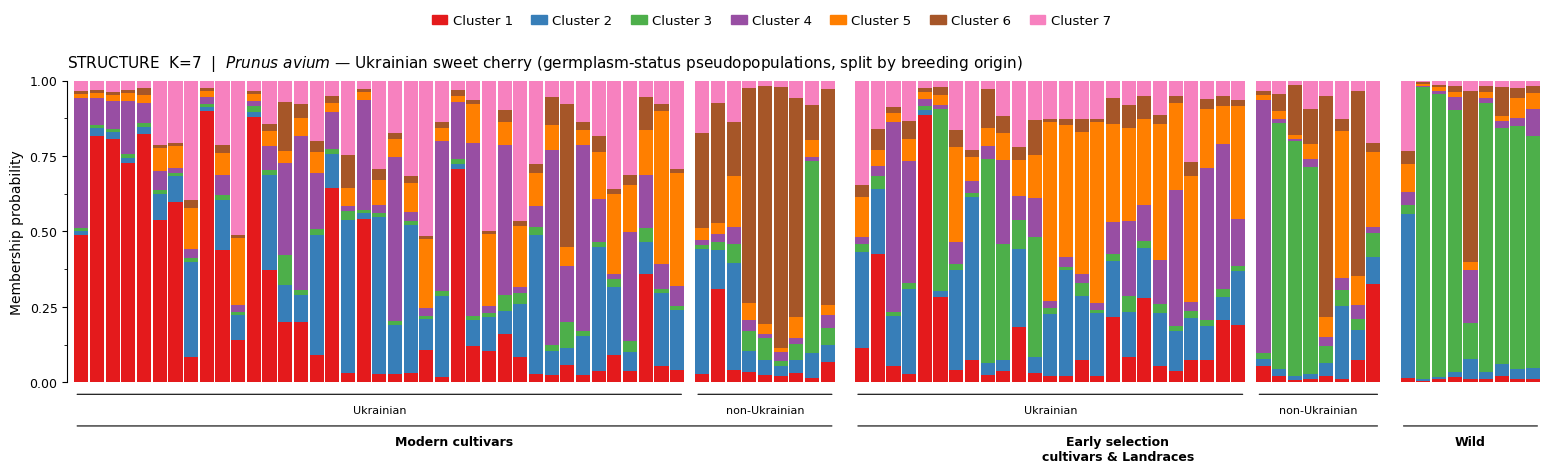

Saved: CherryID_K7_status_x_origin.png


In [ ]:
# ── CELL 7 v9 — DAPC / STRUCTURE membership bar plot ──────────────────────────
#   CHERRY germplasm pseudopopulations, ONE panel, TWO-TIER grouping:
#     outer = germplasm STATUS   (Modern | Early-sel.+Landrace | Wild)
#     inner = breeding ORIGIN    (Ukrainian | non-Ukrainian)  — Wild NOT split
#
#   v9 CHANGES
#   1) FIX: STRUCTURE serial != metadata N_n.  The CLUMPP outfile is the
#      clone-corrected run renumbered 1..90, while N_n runs 1..94 and includes
#      the removed clones.  v8 mapped serial->N_n directly, which shifted
#      metadata from serial 24 onward and silently dropped N_n 91-94
#      (LAP, 107, 19, Tunisian - all non-Ukrainian), giving 13 foreign
#      accessions instead of 17.  Serials are now mapped through the retained
#      N_n order (or an explicit samplekey file).
#   2) SHARED ORDERING across panels:  ORDER_MODE="write" sorts by the panel's
#      own Q and saves the accession order; ORDER_MODE="read" reuses that order
#      so panel B is bar-for-bar comparable with panel A.
#   3) Records now carry both the display name and the metadata `code`, so the
#      DAPC and STRUCTURE branches are keyed identically.
#
#   NOT real demes: clustering was UNSUPERVISED. Grouping is a display ordering.
# ─────────────────────────────────────────────────────────────────────────────
import re, os, csv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import MultipleLocator
# from google.colab import files

# ── ★ PATHS ───────────────────────────────────────────────────────────────────
#INPUT_FILE = "/content/DAPC_K3_Qscores_ed.csv"   # panel A  (run first)
INPUT_FILE = "/content/CherryID_K7.outfile"    # panel B  (run second)
METAFILE   = "/content/metadata.txt"

# ── ★ ORDERING ────────────────────────────────────────────────────────────────
#   "write" -> Q-sort this panel and SAVE the accession order   (use for panel A)
#   "read"  -> REUSE the saved order, no re-sorting             (use for panel B)
#   "none"  -> Q-sort, save nothing (single stand-alone figure)
ORDER_MODE = "read"
ORDER_FILE = "/content/panel_order.txt"

# ── ★ CLONE CORRECTION (STRUCTURE input only) ────────────────────────────────
#   N_n of the accessions removed before the 90-individual STRUCTURE run.
EXCLUDED_NN = {24, 26, 52, 65}      # OTR/2, TAY/1, ZOR/1, OLE/2
#   Optional override: samplekey.tsv from CELL 6 (columns serial, sample_name).
#   If set, it takes precedence over EXCLUDED_NN.
SAMPLEKEY = None

# ── ★ SETTINGS ────────────────────────────────────────────────────────────────
NA_ORIGIN_IS_UKRAINIAN = True   # origin "NA" (only AVLV1) -> Ukrainian if True

STATUS_TO_GROUP = {
    "Modern cultivar": "Modern cultivars", "NA": "Modern cultivars",
    "Early selection cultivar": "Early selection cultivars & Landraces",
    "Landrace": "Early selection cultivars & Landraces",
    "Wild": "Wild",
}
SUBGROUP_PLAN = [
    ("Modern cultivars",                      "Ukrainian"),
    ("Modern cultivars",                      "non-Ukrainian"),
    ("Early selection cultivars & Landraces", "Ukrainian"),
    ("Early selection cultivars & Landraces", "non-Ukrainian"),
    ("Wild",                                  None),
]
OUTER_LABEL = {
    "Modern cultivars": "Modern cultivars",
    "Early selection cultivars & Landraces": "Early selection\ncultivars & Landraces",
    "Wild": "Wild",
}
ALL_COLORS = ["#E41A1C", "#377EB8", "#4DAF4A", "#984EA3",
              "#FF7F00", "#A65628", "#F781BF", "#999999"]     # R Set1

# ═══════════════════════════════════════════════════════════════════════════════
# 1. METADATA
# ═══════════════════════════════════════════════════════════════════════════════
meta, order_nn = {}, []          # code -> {status, origin, nn} ; N_n in file order
with open(METAFILE, encoding="utf-8") as fh:
    for row in csv.DictReader(fh, delimiter="\t"):
        code = row["sample_name"].strip()
        meta[code] = dict(status=(row["status"] or "").strip(),
                          origin=(row.get("origin") or "NA").strip() or "NA",
                          nn=int(row["N_n"]))
        order_nn.append((int(row["N_n"]), code))
order_nn.sort()
codes = list(meta)
print(f"Metadata: {len(meta)} accessions.")

def attach_meta(full_name):
    """whole-token join: return (code, metadata) or (None, None)"""
    toks = full_name.split()
    hit = [c for c in codes if c in toks]
    return (hit[0], meta[hit[0]]) if len(hit) == 1 else (None, None)

def origin_bin(o):
    if o == "Ukraine":         return "Ukrainian"
    if o in ("NA", "", None):  return "Ukrainian" if NA_ORIGIN_IS_UKRAINIAN else "non-Ukrainian"
    return "non-Ukrainian"

# ═══════════════════════════════════════════════════════════════════════════════
# 2. PARSE Q-MATRIX
# ═══════════════════════════════════════════════════════════════════════════════
with open(INPUT_FILE) as fh:
    first = fh.readline()
delim   = "\t" if "\t" in first else ","
is_dapc = ("Cluster_1" in first) or ("sample_name" in first)
records, unmatched = [], []

if is_dapc:
    source_label = "DAPC"
    with open(INPUT_FILE, newline="") as fh:
        reader = csv.DictReader(fh, delimiter=delim)
        clust_cols = [c for c in reader.fieldnames if c.startswith("Cluster_")]
        K = len(clust_cols)
        for row in reader:
            name = row["sample_name"].strip()
            code, m = attach_meta(name)
            if m is None:
                unmatched.append(name); continue
            records.append(dict(code=code, name=name,
                                q=[float(row[c]) for c in clust_cols],
                                status=m["status"], origin=m["origin"]))
    print(f"DAPC parsed: {len(records)} individuals, K={K}")

else:
    source_label = "STRUCTURE"
    # --- serial -> code map (v9 fix) ---
    if SAMPLEKEY:
        serial_to_code = {}
        with open(SAMPLEKEY, encoding="utf-8") as fh:
            for row in csv.DictReader(fh, delimiter="\t"):
                serial_to_code[int(row["serial"])] = row["sample_name"].strip()
        src = f"samplekey ({os.path.basename(SAMPLEKEY)})"
    else:
        retained = [c for nn, c in order_nn if nn not in EXCLUDED_NN]
        serial_to_code = {i + 1: c for i, c in enumerate(retained)}
        src = f"metadata minus EXCLUDED_NN={sorted(EXCLUDED_NN)}"
    print(f"Serial map from {src}: {len(serial_to_code)} serials.")

    line_pat = re.compile(r'^\s*(\d+)\s+\d+\s+\(\s*\d+\s*\)\s+\d+\s*:\s+([\d. ]+)')
    with open(INPUT_FILE) as fh:
        for line in fh:
            mo = line_pat.match(line)
            if not mo: continue
            serial = int(mo.group(1)); q = [float(v) for v in mo.group(2).split()]
            code = serial_to_code.get(serial)
            if code is None:
                unmatched.append(f"serial {serial}"); continue
            m = meta[code]
            records.append(dict(code=code, name=code, q=q,
                                status=m["status"], origin=m["origin"]))
    K = len(records[0]["q"]) if records else 0
    if len(records) != len(serial_to_code):
        raise ValueError(f"Serial map has {len(serial_to_code)} entries but "
                         f"{len(records)} individuals were parsed — check EXCLUDED_NN.")
    print(f"STRUCTURE parsed: {len(records)} individuals, K={K}")

if unmatched:
    raise ValueError(f"Unmatched samples: {unmatched}")
assert records, "No individuals parsed."
assert K <= len(ALL_COLORS), f"K={K} exceeds palette."
CLUSTER_COLORS = ALL_COLORS[:K]

def status_group(r): return STATUS_TO_GROUP[r["status"]]
def qsort_key(r):
    d = int(np.argmax(r["q"]))
    return (d, -r["q"][d])

# ═══════════════════════════════════════════════════════════════════════════════
# 3. LAYOUT
# ═══════════════════════════════════════════════════════════════════════════════
if ORDER_MODE == "read":
    with open(ORDER_FILE, encoding="utf-8") as fh:
        saved = [ln.strip() for ln in fh if ln.strip()]
    here, there = {r["code"] for r in records}, set(saved)
    if here != there:
        raise ValueError(f"Saved order does not match this dataset.\n"
                         f"  missing from order file: {sorted(here - there)}\n"
                         f"  extra in order file:     {sorted(there - here)}")
    rank = {c: i for i, c in enumerate(saved)}
    sort_key = lambda r: rank[r["code"]]
    print(f"Ordering: reusing {os.path.basename(ORDER_FILE)} ({len(saved)} accessions).")
else:
    sort_key = qsort_key
    print("Ordering: Q-sorted within sub-blocks.")

GAP, SUBGAP = 1.2, 0.6
ordered, xpos = [], []
sub_spans, outer_spans = [], []
cursor, prev_status = 0.0, None

for status_g, sub in SUBGROUP_PLAN:
    recs = [r for r in records
            if status_group(r) == status_g
            and (sub is None or origin_bin(r["origin"]) == sub)]
    if not recs:
        continue
    if prev_status is not None:
        cursor += GAP if status_g != prev_status else SUBGAP
    recs.sort(key=sort_key)
    x0 = cursor
    for r in recs:
        ordered.append(r); xpos.append(cursor); cursor += 1
    x1 = cursor - 1
    if sub is not None:
        sub_spans.append((sub, x0, x1))
    outer_spans.append((status_g, x0, x1))
    prev_status = status_g
    print(f"   {status_g:<38} {str(sub):<14} n={len(recs)}")

merged = {}
for s, x0, x1 in outer_spans:
    merged[s] = (min(merged[s][0], x0), max(merged[s][1], x1)) if s in merged else (x0, x1)
outer_spans = [(s, *merged[s]) for s in dict.fromkeys(s for s, _, _ in outer_spans)]

if ORDER_MODE == "write":
    with open(ORDER_FILE, "w", encoding="utf-8") as fh:
        fh.write("\n".join(r["code"] for r in ordered) + "\n")
    print(f"Ordering saved -> {ORDER_FILE}  (set ORDER_MODE='read' for the next panel)")

xpos = np.array(xpos)
Q = np.array([r["q"] for r in ordered])

# ═══════════════════════════════════════════════════════════════════════════════
# 4. PLOT
# ═══════════════════════════════════════════════════════════════════════════════
BAR_W = 0.9
fig, ax = plt.subplots(figsize=(16, 5.2))
fig.subplots_adjust(top=0.84, bottom=0.26, left=0.06, right=0.985)

bottoms = np.zeros(len(ordered))
for k in range(K):
    ax.bar(xpos, Q[:, k], bottom=bottoms, width=BAR_W,
           color=CLUSTER_COLORS[k], linewidth=0)
    bottoms += Q[:, k]

def bracket(x0, x1, y, label, y_txt, fs, bold):
    xl, xr = x0 - BAR_W/2, x1 + BAR_W/2
    ax.annotate("", xy=(xr, y), xytext=(xl, y),
                xycoords=("data", "axes fraction"),
                textcoords=("data", "axes fraction"), annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color="black", lw=0.8))
    if label:
        ax.text((xl + xr)/2, y_txt, label, ha="center", va="top",
                transform=ax.get_xaxis_transform(),
                fontsize=fs, fontweight=("bold" if bold else "normal"), clip_on=False)

for lab, x0, x1 in sub_spans:
    bracket(x0, x1, -0.04, lab, -0.075, 8.0, False)
for status_g, x0, x1 in outer_spans:
    bracket(x0, x1, -0.145, OUTER_LABEL[status_g], -0.175, 9.0, True)

ax.set_xlim(xpos[0] - BAR_W, xpos[-1] + BAR_W)
ax.set_ylim(0, 1)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.yaxis.set_minor_locator(MultipleLocator(0.125))
ax.set_ylabel("Membership probability", fontsize=10)
ax.set_xticks([])
ax.tick_params(axis="y", labelsize=9)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.spines["left"].set_linewidth(0.8)

patches = [mpatches.Patch(color=CLUSTER_COLORS[k], label=f"Cluster {k+1}")
           for k in range(K)]
fig.legend(handles=patches, loc="upper center", bbox_to_anchor=(0.5, 0.99),
           ncol=K, frameon=False, fontsize=9.5, handlelength=1.2,
           handletextpad=0.4, columnspacing=1.4)

k_in_fname = re.search(r'[Kk](\d+)', os.path.basename(INPUT_FILE))
k_label    = f"K={k_in_fname.group(1)}" if k_in_fname else f"K={K}"
ax.set_title(f"{source_label}  {k_label}  |  $Prunus$ $avium$ — Ukrainian sweet cherry "
             f"(germplasm-status pseudopopulations, split by breeding origin)",
             fontsize=11, loc="left", pad=10)

# ═══════════════════════════════════════════════════════════════════════════════
# 5. SAVE @ 600 dpi
# ═══════════════════════════════════════════════════════════════════════════════
base    = os.path.splitext(os.path.basename(INPUT_FILE))[0]
OUT_PNG = f"{base}_status_x_origin.png"
fig.savefig(OUT_PNG, dpi=600, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_PNG}")
# files.download(OUT_PNG)

## 🍒DAPC BIC plot v2
### UKR_CherryID project "breeding germplasm pseudopopulation vesion" 🍒

In [ ]:
# ── CELL — DAPC BIC plot v2  (Structure Harvester visual style) ─────────────────
# Input : BIC_table.csv  (columns: K, BIC_mean, BIC_SD, BIC_SE, delta_BIC)
#
# Best K = K with the LOWEST mean BIC (the actual DAPC selection criterion).
# Secondary K = a genuine interior local minimum (lower than both neighbours),
#               if one exists; None for a single-troughed curve.
# Set BEST_K / SECONDARY_K to an integer to override auto-detection.
# ─────────────────────────────────────────────────────────────────────────────
import os, csv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from google.colab import files

# ── ★ USER SETTINGS ───────────────────────────────────────────────────────────
BIC_FILE    = "/content/BIC_table.csv"
BEST_K      = None    # None = auto (min BIC) | integer = manual override
SECONDARY_K = None    # None = auto           | integer = manual override

# ── 1. Load table ─────────────────────────────────────────────────────────────
ks, bic_mean, bic_se, delta_bic = [], [], [], []
with open(BIC_FILE, newline="") as fh:
    for row in csv.DictReader(fh):
        ks.append(int(row["K"]))
        bic_mean.append(float(row["BIC_mean"]))
        bic_se.append(float(row["BIC_SE"]))
        delta_bic.append(np.nan if row["delta_BIC"].strip() == "NA"
                         else float(row["delta_BIC"]))
ks       = np.array(ks)
bic_mean = np.array(bic_mean)
bic_se   = np.array(bic_se)
delta_arr = np.array(delta_bic)

# ── 2. Select Best K (= global BIC minimum) and optional Secondary K ──────────
if BEST_K is None:
    BEST_K = int(ks[np.argmin(bic_mean)])

if SECONDARY_K is None:
    cand = [(bic_mean[i], int(ks[i]))
            for i in range(1, len(ks) - 1)
            if bic_mean[i] < bic_mean[i-1] and bic_mean[i] < bic_mean[i+1]
            and int(ks[i]) != BEST_K]
    SECONDARY_K = min(cand)[1] if cand else None
if SECONDARY_K == BEST_K:
    SECONDARY_K = None

# BIC values for the chosen K's — recompute AFTER selection (was the bug)
best_bic = float(bic_mean[ks == BEST_K][0])
sec_bic  = float(bic_mean[ks == SECONDARY_K][0]) if SECONDARY_K is not None else None

print(f"Best K (min BIC)  : K={BEST_K}  (BIC={best_bic:.2f})")
if SECONDARY_K:
    print(f"Secondary K       : K={SECONDARY_K}  (BIC={sec_bic:.2f})")
else:
    print("Secondary K       : none (single-troughed curve)")

# ── 3. delta_BIC table (diagnostic only — does NOT drive selection) ───────────
print("\n  K   BIC_mean   delta_BIC")
for k, b, d in zip(ks, bic_mean, delta_arr):
    tag = "  ← BEST K" if k == BEST_K else ("  ← SECONDARY K" if k == SECONDARY_K else "")
    print(f"  {k:2d}  {b:8.2f}   {'NA' if np.isnan(d) else f'{d:7.2f}'}{tag}")

# ── 4. Plot ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(ks, bic_mean, yerr=bic_se,
            color="#1f77b4", linewidth=1.5,
            marker="o", markersize=6,
            markerfacecolor="white", markeredgewidth=1.5,
            elinewidth=1.0, capsize=3, zorder=3, label="_nolegend_")

# Best K — red filled circle + dashed vertical
ax.plot(BEST_K, best_bic, marker="o", markersize=10, color="#d62728", zorder=5,
        label=f"Best K = {BEST_K}  (BIC = {best_bic:.2f})")
ax.axvline(BEST_K, color="#d62728", linestyle="--", linewidth=0.9, alpha=0.65, zorder=2)
ax.annotate(f"{best_bic:.2f}", xy=(BEST_K, best_bic), xytext=(6, 6),
            textcoords="offset points", fontsize=9, color="#d62728")

# Secondary K — orange triangle + dotted vertical (only if one exists)
if SECONDARY_K is not None:
    ax.plot(SECONDARY_K, sec_bic, marker="^", markersize=9, color="#ff7f0e", zorder=5,
            label=f"Secondary K = {SECONDARY_K}  (BIC = {sec_bic:.2f})")
    ax.axvline(SECONDARY_K, color="#ff7f0e", linestyle=":", linewidth=0.9, alpha=0.65, zorder=2)
    ax.annotate(f"{sec_bic:.2f}", xy=(SECONDARY_K, sec_bic), xytext=(6, -14),
                textcoords="offset points", fontsize=9, color="#ff7f0e")

ax.set_xlabel("Number of clusters (K)", fontsize=12)
ax.set_ylabel("BIC (mean \u00b1 SE)", fontsize=12)
ax.set_title("BIC vs. number of clusters\n(1000 replicates)", fontsize=13)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.7)
ax.legend(fontsize=10, frameon=False, loc="upper center")

plt.tight_layout()

# ── 5. Save + download ────────────────────────────────────────────────────────
base    = os.path.splitext(os.path.basename(BIC_FILE))[0]
OUT_PNG = f"{base}_plot.png"
OUT_SVG = f"{base}_plot.svg"
fig.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
fig.savefig(OUT_SVG, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_PNG}  |  {OUT_SVG}")
#files.download(OUT_PNG)
#files.download(OUT_SVG)

# PCoA [Factorial anaanalysis]

## 🍒PCoA on DARwin factorial analysis data v1
### UKR_CherryID project "breeding germplasm pseudopopulation vesion" 🍒

✓ Loaded 91 units, 20 axes from 94_sweet_cherry_18_SSR_T_square_root.AFT
  Axis 1: 9.38%   Axis 2: 6.97%   Axis 3: 5.90%
  provenance:
     Transformed dissimilarity from: 94_sweet_cherry_18_SSR.dis
     Applied transformation: Square root
     Dissimilarity calculated from data file: 94_sweet_cherry_18_SSR.var (type:'allelic')
     User selection   Units: 91/94 and Loci: 18/18
     Dissimilarity index: Simple matching
     Pairwise locus deletion - Remove locus with missing data for the current unit pair (50 % of valid data required for each unit pair)
     10000 bootstraps

✓ all units matched to metadata
  in metadata but not in PCoA (dropped by DARwin): ['MEL/2', 'TEM/1-2', '77']
  clone-corrected: 91 -> 87 units


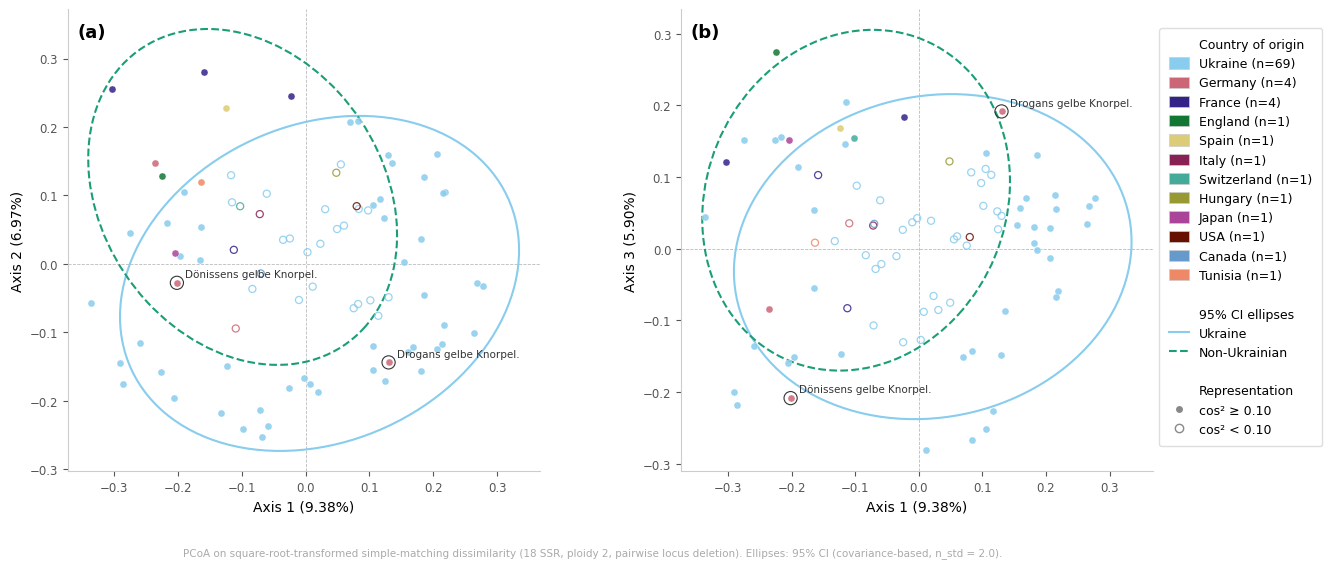

✓  PCoA_combined_18SSR.png / .svg

Variance explained (DARwin inertia):
  Axis 1: eigenvalue 0.02370    9.38%   cumulative  9.38%
  Axis 2: eigenvalue 0.01762    6.97%   cumulative 16.35%
  Axis 3: eigenvalue 0.01491    5.90%   cumulative 22.25%
  Axis 4: eigenvalue 0.01341    5.31%   cumulative 27.56%
  Axis 5: eigenvalue 0.01181    4.68%   cumulative 32.24%
  Axis 6: eigenvalue 0.01048    4.15%   cumulative 36.39%
  Axis 7: eigenvalue 0.01024    4.05%   cumulative 40.44%
  Axis 8: eigenvalue 0.00898    3.55%   cumulative 43.99%
  Axis 9: eigenvalue 0.00775    3.07%   cumulative 47.06%
  Axis 10: eigenvalue 0.00769    3.04%   cumulative 50.10%
  Axis 11: eigenvalue 0.00701    2.78%   cumulative 52.88%
  Axis 12: eigenvalue 0.00634    2.51%   cumulative 55.39%
  Axis 13: eigenvalue 0.00630    2.49%   cumulative 57.88%
  Axis 14: eigenvalue 0.00576    2.28%   cumulative 60.16%
  Axis 15: eigenvalue 0.00555    2.20%   cumulative 62.36%
  Axis 16: eigenvalue 0.00518    2.05%   cumulative 

In [ ]:
# ── CELL 7 v4 ─────────────────────────────────────────────────────────────────
# PCoA two-panel figure (Axis1×2 and Axis1×3) with 95% CI ellipses
# v3 -> v4 : input switched from GenAlEx PCoA.csv to DARwin factorial analysis
#
# Input : 94_sweet_cherry_18_SSR_T_square_root.AFT       (coords + eigenvalues)
#         94_sweet_cherry_18_SSR_T_square_root_Cos.DON   (cos^2 x1000, optional)
#         metadata.txt                                   (merge key = N_n)
#
# Distance : Simple matching (allelic, ploidy 2), 18 SSR, 91/94 units,
#            pairwise locus deletion, then Square-root transformation
#            -> metric/Euclidean, which is what PCoA requires.
# Colours  : reused from the iTOL datasets so tree and PCoA agree.
# ──────────────────────────────────────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms
import matplotlib.lines as mlines
import re, warnings
warnings.filterwarnings("ignore")

AFT_FILE  = "94_sweet_cherry_18_SSR_T_square_root.AFT"
COS_FILE  = "94_sweet_cherry_18_SSR_T_square_root_Cos.DON"   # set None to skip
META_FILE = "metadata.txt"

COLOR_BY   = "origin"      # "origin" | "origin_binary" | "status"
DROP_CLONES = True         # drop OTR/2, TAY/1, ZOR/1, OLE/2 (clone-corrected, as in DAPC)
COS2_MIN    = 0.10         # points below this cos^2 on the plotted plane are drawn hollow
ANNOTATE    = ["DRO/1", "110"]   # sample_name codes to label on the plot

# ── 1. PARSE DARwin .AFT ──────────────────────────────────────────────────────
def parse_darwin_aft(path):
    """Return (coords_df, axis_pct, eigenvalues, provenance_lines)."""
    with open(path, "r", encoding="cp1252", errors="replace") as f:
        lines = [l.rstrip("\n") for l in f]

    if not lines[0].startswith("@DARwin"):
        raise ValueError("Not a DARwin file: " + lines[0])
    n_units, n_axes = (int(x) for x in lines[1].split("\t")[:2])

    # coordinate block: starts after the 'Unit\tAxis 1...' header
    hdr = next(i for i, l in enumerate(lines) if l.split("\t")[0].strip() == "Unit")
    rows = []
    for l in lines[hdr + 1: hdr + 1 + n_units]:
        c = l.split("\t")
        rows.append([int(c[0])] + [float(v) for v in c[1:n_axes + 1]])
    coords = pd.DataFrame(rows, columns=["N_n"] + [f"Axis{k}" for k in range(1, n_axes + 1)])

    # eigenvalue / inertia block
    eig = next(i for i, l in enumerate(lines) if l.startswith("Axis\tEigenvalue"))
    axis_pct, eigenvalues = {}, {}
    for l in lines[eig + 1:]:
        c = [x for x in l.split("\t") if x.strip() != ""]
        if len(c) < 3:
            break
        k = int(c[0]); eigenvalues[k] = float(c[1]); axis_pct[k] = float(c[2])

    prov = [l for l in lines[eig:] if re.match(r"^(Dissimilarity|Applied|User|Transformed|Pairwise|\d+ bootstraps)", l)]
    return coords, axis_pct, eigenvalues, prov


def parse_darwin_cos(path, n_axes):
    """DARwin stores cos^2 x 1000 as integers."""
    with open(path, "r", encoding="cp1252", errors="replace") as f:
        lines = [l.rstrip("\n") for l in f]
    n_units = int(lines[1].split("\t")[0])
    hdr = next(i for i, l in enumerate(lines) if l.split("\t")[0].strip() == "None")
    rows = []
    for l in lines[hdr + 1: hdr + 1 + n_units]:
        c = l.split("\t")
        rows.append([int(c[0])] + [float(v) / 1000.0 for v in c[1:n_axes + 1]])
    return pd.DataFrame(rows, columns=["N_n"] + [f"Cos2_{k}" for k in range(1, n_axes + 1)])


coords_df, axis_pct, eigenvalues, provenance = parse_darwin_aft(AFT_FILE)
n_axes = sum(1 for c in coords_df.columns if c.startswith("Axis"))
print(f"✓ Loaded {len(coords_df)} units, {n_axes} axes from {AFT_FILE}")
print(f"  Axis 1: {axis_pct.get(1,0):.2f}%   Axis 2: {axis_pct.get(2,0):.2f}%   Axis 3: {axis_pct.get(3,0):.2f}%")
print("  provenance:")
for p in provenance:
    print("    ", p)

# ── 2. MERGE METADATA (key = N_n) ─────────────────────────────────────────────
meta = pd.read_csv(META_FILE, sep="\t", dtype={"N_n": int})
meta.columns = meta.columns.str.strip()
for c in ["sample_name", "status", "origin", "harmonised_name", "clone_of"]:
    meta[c] = meta[c].astype(str).str.strip()

df = coords_df.merge(
    meta[["N_n", "sample_name", "status", "origin", "harmonised_name", "clone_of"]],
    on="N_n", how="left")

missing = df[df["sample_name"].isna()]["N_n"].tolist()
print(f"\n{'⚠ unmatched N_n: ' + str(missing) if missing else '✓ all units matched to metadata'}")
absent = sorted(set(meta["N_n"]) - set(coords_df["N_n"]))
print(f"  in metadata but not in PCoA (dropped by DARwin): "
      f"{[meta.loc[meta.N_n==i,'sample_name'].iat[0] for i in absent]}")

if COS_FILE:
    df = df.merge(parse_darwin_cos(COS_FILE, n_axes), on="N_n", how="left")

if DROP_CLONES:
    clones = {"OTR/2", "TAY/1", "ZOR/1", "OLE/2"}
    n0 = len(df)
    df = df[~df["sample_name"].isin(clones)].copy()
    print(f"  clone-corrected: {n0} -> {len(df)} units")

# ── 3. COLOUR SCHEMES (identical to the iTOL datasets) ────────────────────────
GREY = "#5B5B5B"

ORIGIN_MAP = {
    "Ukraine": "#88CCEE", "Germany": "#CC6677", "France": "#332288",
    "England": "#117733", "Spain": "#DDCC77", "Italy": "#882255",
    "Switzerland": "#44AA99", "Hungary": "#999933", "Japan": "#AA4499",
    "USA": "#661100", "Canada": "#6699CC", "Tunisia": "#EE8866", "NA": GREY,
}
ORIGIN_ORDER = ["Ukraine", "Germany", "France", "England", "Spain", "Italy",
                "Switzerland", "Hungary", "Japan", "USA", "Canada", "Tunisia", "NA"]

BINARY_MAP   = {"Ukraine": "#88CCEE", "Non-Ukrainian": "#1B9E77", "NA": GREY}
BINARY_ORDER = ["Ukraine", "Non-Ukrainian", "NA"]

STATUS_MAP = {"Modern cultivar": "#0072B2", "Early selection cultivar": "#56B4E9",
              "Landrace": "#E69F00", "Wild": "#009E73", "NA": GREY}
STATUS_ORDER = ["Modern cultivar", "Early selection cultivar", "Landrace", "Wild", "NA"]

if COLOR_BY == "origin":
    df["grp"] = df["origin"]
    COLOR_MAP, GRP_ORDER, LEG_TITLE = ORIGIN_MAP, ORIGIN_ORDER, "Country of origin"
elif COLOR_BY == "origin_binary":
    df["grp"] = np.where(df["origin"] == "Ukraine", "Ukraine",
                np.where(df["origin"] == "NA", "NA", "Non-Ukrainian"))
    COLOR_MAP, GRP_ORDER, LEG_TITLE = BINARY_MAP, BINARY_ORDER, "Origin"
elif COLOR_BY == "status":
    df["grp"] = df["status"]
    COLOR_MAP, GRP_ORDER, LEG_TITLE = STATUS_MAP, STATUS_ORDER, "Germplasm status"
else:
    raise ValueError("COLOR_BY must be origin | origin_binary | status")

GRP_ORDER = [g for g in GRP_ORDER if g in set(df["grp"])]
PRETTY = {"NA": "Unresolved"}
lab = lambda g: PRETTY.get(g, g)

# Ellipses: Ukrainian vs non-Ukrainian germplasm (identity of the UA pool)
ELLIPSE_GROUPS = {
    "Ukraine":       {"mask": df["origin"] == "Ukraine",                      "color": "#88CCEE", "lw": 1.5, "ls": "-"},
    "Non-Ukrainian": {"mask": ~df["origin"].isin(["Ukraine", "NA"]),          "color": "#1B9E77", "lw": 1.5, "ls": "--"},
}

# ── 4. ELLIPSE FUNCTION (unchanged from v3) ───────────────────────────────────
def confidence_ellipse(x, y, ax, n_std=2.0, edgecolor="black", lw=1.2, ls="-", **kw):
    if len(x) < 3:
        return
    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    rx, ry = np.sqrt(1 + pearson), np.sqrt(1 - pearson)
    ell = Ellipse((0, 0), width=rx * 2, height=ry * 2, facecolor="none",
                  edgecolor=edgecolor, linewidth=lw, linestyle=ls, **kw)
    sx, sy = np.sqrt(cov[0, 0]) * n_std, np.sqrt(cov[1, 1]) * n_std
    t = (transforms.Affine2D().rotate_deg(45).scale(sx, sy)
         .translate(np.mean(x), np.mean(y)))
    ell.set_transform(t + ax.transData)
    ax.add_patch(ell)

# ── 5. PANEL DRAW ─────────────────────────────────────────────────────────────
def draw_panel(ax, df, xcol, ycol, xpct, ypct, panel_label):
    kx, ky = xcol[-1], ycol[-1]
    if COS_FILE and f"Cos2_{kx}" in df:
        well = (df[f"Cos2_{kx}"] + df[f"Cos2_{ky}"]) >= COS2_MIN
    else:
        well = pd.Series(True, index=df.index)

    for g in GRP_ORDER:
        m = df["grp"] == g
        # well-represented: filled
        s = m & well
        ax.scatter(df.loc[s, xcol], df.loc[s, ycol], c=COLOR_MAP[g], s=26, alpha=0.85,
                   edgecolors="white", linewidths=0.3, zorder=4)
        # poorly represented on this plane: hollow
        s = m & ~well
        ax.scatter(df.loc[s, xcol], df.loc[s, ycol], facecolors="none", s=26,
                   edgecolors=COLOR_MAP[g], linewidths=0.9, alpha=0.85, zorder=3)

    for cfg in ELLIPSE_GROUPS.values():
        sub = df[cfg["mask"].reindex(df.index, fill_value=False)]
        confidence_ellipse(sub[xcol].values, sub[ycol].values, ax, n_std=2.0,
                           edgecolor=cfg["color"], lw=cfg["lw"], ls=cfg["ls"], zorder=2)

    for code in ANNOTATE:
        r = df[df["sample_name"] == code]
        if len(r):
            ax.annotate(r["harmonised_name"].iat[0].split(" [")[0],
                        (r[xcol].iat[0], r[ycol].iat[0]),
                        textcoords="offset points", xytext=(6, 4),
                        fontsize=7.5, color="#333333", zorder=6)
            ax.scatter(r[xcol], r[ycol], facecolors="none", edgecolors="#333333",
                       s=90, linewidths=0.8, zorder=5)

    ax.axhline(0, color="#BBBBBB", lw=0.6, ls="--", zorder=1)
    ax.axvline(0, color="#BBBBBB", lw=0.6, ls="--", zorder=1)
    ax.set_xlabel(f"Axis {kx} ({xpct:.2f}%)", fontsize=10)
    ax.set_ylabel(f"Axis {ky} ({ypct:.2f}%)", fontsize=10)
    ax.text(0.02, 0.97, panel_label, transform=ax.transAxes,
            fontsize=13, fontweight="bold", va="top", ha="left")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CCCCCC"); ax.spines["bottom"].set_color("#CCCCCC")
    ax.tick_params(colors="#555555", labelsize=8.5)

# ── 6. LEGEND ─────────────────────────────────────────────────────────────────
def build_legend_handles(df):
    h = [mpatches.Patch(facecolor="none", edgecolor="none", label=LEG_TITLE)]
    for g in GRP_ORDER:
        n = int((df["grp"] == g).sum())
        h.append(mpatches.Patch(facecolor=COLOR_MAP[g], edgecolor="#CCCCCC",
                                linewidth=0.5, label=f"{lab(g)} (n={n})"))
    h += [mpatches.Patch(facecolor="none", edgecolor="none", label=" "),
          mpatches.Patch(facecolor="none", edgecolor="none", label="95% CI ellipses")]
    for name, cfg in ELLIPSE_GROUPS.items():
        if int(cfg["mask"].sum()) >= 3:
            h.append(mlines.Line2D([], [], color=cfg["color"], linewidth=1.5,
                                   linestyle=cfg["ls"], label=name))
    if COS_FILE:
        h += [mpatches.Patch(facecolor="none", edgecolor="none", label=" "),
              mpatches.Patch(facecolor="none", edgecolor="none", label="Representation"),
              mlines.Line2D([], [], marker="o", color="none", markerfacecolor="#888888",
                            markeredgecolor="white", markersize=6, label=f"cos² ≥ {COS2_MIN:.2f}"),
              mlines.Line2D([], [], marker="o", color="none", markerfacecolor="none",
                            markeredgecolor="#888888", markersize=6, label=f"cos² < {COS2_MIN:.2f}")]
    return h

# ── 7. COMPOSE ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"wspace": 0.30})
fig.patch.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("white")

draw_panel(axes[0], df, "Axis1", "Axis2", axis_pct.get(1, 0), axis_pct.get(2, 0), "(a)")
draw_panel(axes[1], df, "Axis1", "Axis3", axis_pct.get(1, 0), axis_pct.get(3, 0), "(b)")

fig.legend(handles=build_legend_handles(df), loc="center left",
           bbox_to_anchor=(0.9, 0.5), fontsize=9, title_fontsize=9,
           frameon=True, framealpha=0.95, edgecolor="#DDDDDD",
           handlelength=1.6, handleheight=1.0, borderpad=0.8)

fig.text(0.5, -0.03,
         "PCoA on square-root-transformed simple-matching dissimilarity (18 SSR, ploidy 2, "
         "pairwise locus deletion). Ellipses: 95% CI (covariance-based, n_std = 2.0).",
         ha="center", fontsize=7.5, color="#AAAAAA")

plt.tight_layout()
plt.savefig("PCoA_combined_18SSR.png", dpi=300, bbox_inches="tight")
plt.savefig("PCoA_combined_18SSR.svg", format="svg", bbox_inches="tight")
plt.show()
print("✓  PCoA_combined_18SSR.png / .svg")

# ── 8. VARIANCE + REPRESENTATION SUMMARY ──────────────────────────────────────
print("\nVariance explained (DARwin inertia):")
cum = 0
for k in sorted(axis_pct):
    cum += axis_pct[k]
    print(f"  Axis {k}: eigenvalue {eigenvalues[k]:.5f}   {axis_pct[k]:5.2f}%   cumulative {cum:5.2f}%")

if COS_FILE:
    for kx, ky, pl in [(1, 2, "(a) Axis1×2"), (1, 3, "(b) Axis1×3")]:
        q = df[f"Cos2_{kx}"] + df[f"Cos2_{ky}"]
        print(f"\n{pl}: median cos² = {q.median():.3f}; "
              f"{int((q < COS2_MIN).sum())}/{len(df)} units poorly represented (cos² < {COS2_MIN})")
        worst = df.assign(q=q).nsmallest(5, "q")[["harmonised_name", "q"]]
        print("  least well represented:",
              ", ".join(f"{r.harmonised_name.split(' [')[0]} ({r.q:.3f})" for r in worst.itertuples()))

## 🍒PCoA on DARwin factorial analysis data v2
### UKR_CherryID project "breeding germplasm pseudopopulation vesion" 🍒

✓ Loaded 91 units, 20 axes from 94_sweet_cherry_18_SSR_T_square_root.AFT
  Axis 1: 9.38%   Axis 2: 6.97%   Axis 3: 5.90%
  provenance:
     Transformed dissimilarity from: 94_sweet_cherry_18_SSR.dis
     Applied transformation: Square root
     Dissimilarity calculated from data file: 94_sweet_cherry_18_SSR.var (type:'allelic')
     User selection   Units: 91/94 and Loci: 18/18
     Dissimilarity index: Simple matching
     Pairwise locus deletion - Remove locus with missing data for the current unit pair (50 % of valid data required for each unit pair)
     10000 bootstraps

✓ all units matched to metadata
  in metadata but not in PCoA (dropped by DARwin): ['MEL/2', 'TEM/1-2', '77']
  clone-corrected: 91 -> 87 units

GI ('Melitopol Cherry') cultivars plotted (4): Anons, Kazka, Krupnoplidna, Talisman
⚠ GI cultivars NOT in this ordination (2): Temporion, Burlat
  -> in metadata but dropped by DARwin (missing data) or clone-corrected.
  -> the caption must say 4, not 6.

ellipse groups (

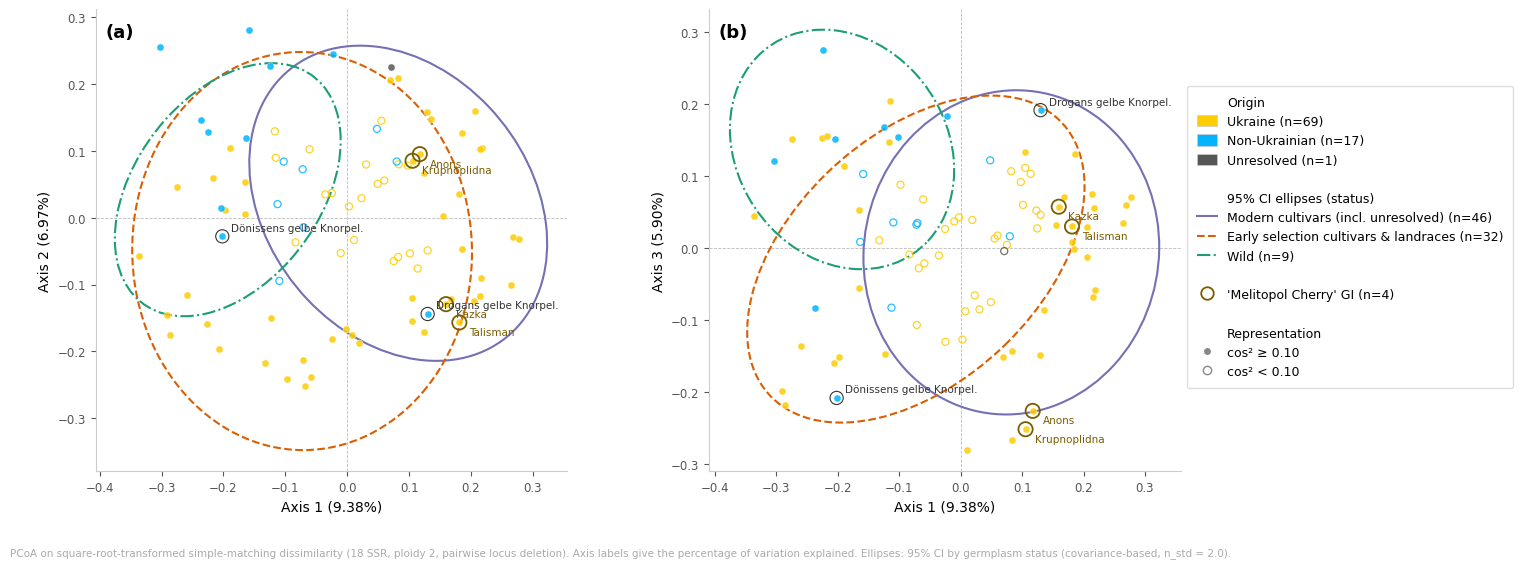

✓  PCoA_combined_18SSR.png / .svg

Variation explained (DARwin reports this column as 'Inertia%'):
  Axis 1: eigenvalue 0.02370    9.38%   cumulative  9.38%
  Axis 2: eigenvalue 0.01762    6.97%   cumulative 16.35%
  Axis 3: eigenvalue 0.01491    5.90%   cumulative 22.25%
  Axis 4: eigenvalue 0.01341    5.31%   cumulative 27.56%
  Axis 5: eigenvalue 0.01181    4.68%   cumulative 32.24%
  Axis 6: eigenvalue 0.01048    4.15%   cumulative 36.39%
  Axis 7: eigenvalue 0.01024    4.05%   cumulative 40.44%
  Axis 8: eigenvalue 0.00898    3.55%   cumulative 43.99%
  Axis 9: eigenvalue 0.00775    3.07%   cumulative 47.06%
  Axis 10: eigenvalue 0.00769    3.04%   cumulative 50.10%
  Axis 11: eigenvalue 0.00701    2.78%   cumulative 52.88%
  Axis 12: eigenvalue 0.00634    2.51%   cumulative 55.39%
  Axis 13: eigenvalue 0.00630    2.49%   cumulative 57.88%
  Axis 14: eigenvalue 0.00576    2.28%   cumulative 60.16%
  Axis 15: eigenvalue 0.00555    2.20%   cumulative 62.36%
  Axis 16: eigenvalue 0.0

In [ ]:
# ── CELL 7 v5 ─────────────────────────────────────────────────────────────────
# PCoA two-panel figure (Axis1×2 and Axis1×3) with 95% CI ellipses
# v3 -> v4 : input switched from GenAlEx PCoA.csv to DARwin factorial analysis
#
# Input : 94_sweet_cherry_18_SSR_T_square_root.AFT       (coords + eigenvalues)
#         94_sweet_cherry_18_SSR_T_square_root_Cos.DON   (cos^2 x1000, optional)
#         metadata.txt                                   (merge key = N_n)
#
# Distance : Simple matching (allelic, ploidy 2), 18 SSR, 91/94 units,
#            pairwise locus deletion, then Square-root transformation
#            -> metric/Euclidean, which is what PCoA requires.
# Colours  : Ukrainian = golden (#FECC02), as in the EABUA PCoA; non-Ukrainian = blue.
# Ellipses : germplasm status, grouped as in the DAPC discussion (not origin).
# Note     : DARwin labels the axis contribution "Inertia%". It is the ordinary
#            percentage of variation explained, and is reported as such here.
# ──────────────────────────────────────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms
import matplotlib.lines as mlines
import re, warnings
warnings.filterwarnings("ignore")

AFT_FILE  = "94_sweet_cherry_18_SSR_T_square_root.AFT"
COS_FILE  = "94_sweet_cherry_18_SSR_T_square_root_Cos.DON"   # set None to skip
META_FILE = "metadata.txt"

COLOR_BY   = "origin_binary"   # "origin_binary" | "origin" | "status"
DROP_CLONES = True         # drop OTR/2, TAY/1, ZOR/1, OLE/2 (clone-corrected, as in DAPC)
COS2_MIN    = 0.10         # points below this cos^2 on the plotted plane are drawn hollow
ANNOTATE    = ["DRO/1", "110"]   # sample_name codes to label on the plot

# "Melitopol Cherry" protected geographical indication (GI), registered by the
# Ministry of Economy of Ukraine on 08.09.2020 (registry: sis.nipo.gov.ua).
# The GI schedule lists: Anons, Valerii Chkalov, Era, Kazka, Krupnoplidna,
# Liubymytsia Turovtseva, Melitopolska chorna (2110), Talisman, Temporion,
# Udivitielna, Burlat.
#   - Valerii Chkalov  : excluded, our accession VAL/3 is not true-to-type
#   - Melitopolska chorna MEL/2, Temporion TEM/1-2, Burlat 77 : in metadata but
#     dropped by DARwin (missing data) -> cannot appear in this ordination
#   - Era, Liubymytsia Turovtseva, Udivitielna : not sampled
GI_CODES = {"ANO/4": "Anons", "SKA/3": "Kazka", "KRU/4": "Krupnoplidna",
            "TAL/4": "Talisman", "TEM/1-2": "Temporion", "77": "Burlat"}
GI_MARK  = True            # ring GI cultivars
GI_LABEL = True            # write their names next to the ring
GI_COLOR = "#7A5C00"

# ── 1. PARSE DARwin .AFT ──────────────────────────────────────────────────────
def parse_darwin_aft(path):
    """Return (coords_df, axis_pct, eigenvalues, provenance_lines)."""
    with open(path, "r", encoding="cp1252", errors="replace") as f:
        lines = [l.rstrip("\n") for l in f]

    if not lines[0].startswith("@DARwin"):
        raise ValueError("Not a DARwin file: " + lines[0])
    n_units, n_axes = (int(x) for x in lines[1].split("\t")[:2])

    # coordinate block: starts after the 'Unit\tAxis 1...' header
    hdr = next(i for i, l in enumerate(lines) if l.split("\t")[0].strip() == "Unit")
    rows = []
    for l in lines[hdr + 1: hdr + 1 + n_units]:
        c = l.split("\t")
        rows.append([int(c[0])] + [float(v) for v in c[1:n_axes + 1]])
    coords = pd.DataFrame(rows, columns=["N_n"] + [f"Axis{k}" for k in range(1, n_axes + 1)])

    # eigenvalue / inertia block
    eig = next(i for i, l in enumerate(lines) if l.startswith("Axis\tEigenvalue"))
    axis_pct, eigenvalues = {}, {}
    for l in lines[eig + 1:]:
        c = [x for x in l.split("\t") if x.strip() != ""]
        if len(c) < 3:
            break
        k = int(c[0]); eigenvalues[k] = float(c[1]); axis_pct[k] = float(c[2])

    prov = [l for l in lines[eig:] if re.match(r"^(Dissimilarity|Applied|User|Transformed|Pairwise|\d+ bootstraps)", l)]
    return coords, axis_pct, eigenvalues, prov


def parse_darwin_cos(path, n_axes):
    """DARwin stores cos^2 x 1000 as integers."""
    with open(path, "r", encoding="cp1252", errors="replace") as f:
        lines = [l.rstrip("\n") for l in f]
    n_units = int(lines[1].split("\t")[0])
    hdr = next(i for i, l in enumerate(lines) if l.split("\t")[0].strip() == "None")
    rows = []
    for l in lines[hdr + 1: hdr + 1 + n_units]:
        c = l.split("\t")
        rows.append([int(c[0])] + [float(v) / 1000.0 for v in c[1:n_axes + 1]])
    return pd.DataFrame(rows, columns=["N_n"] + [f"Cos2_{k}" for k in range(1, n_axes + 1)])


coords_df, axis_pct, eigenvalues, provenance = parse_darwin_aft(AFT_FILE)
n_axes = sum(1 for c in coords_df.columns if c.startswith("Axis"))
print(f"✓ Loaded {len(coords_df)} units, {n_axes} axes from {AFT_FILE}")
print(f"  Axis 1: {axis_pct.get(1,0):.2f}%   Axis 2: {axis_pct.get(2,0):.2f}%   Axis 3: {axis_pct.get(3,0):.2f}%")
print("  provenance:")
for p in provenance:
    print("    ", p)

# ── 2. MERGE METADATA (key = N_n) ─────────────────────────────────────────────
# keep_default_na=False is essential: "NA" is a real category in metadata.txt
# (unresolved identity / unknown origin). Without it pandas turns it into NaN
# and those accessions silently vanish from groups, ellipses and the plot.
meta = pd.read_csv(META_FILE, sep="\t", dtype={"N_n": int}, keep_default_na=False)
meta.columns = meta.columns.str.strip()
for c in ["sample_name", "status", "origin", "harmonised_name", "clone_of"]:
    meta[c] = meta[c].astype(str).str.strip()

df = coords_df.merge(
    meta[["N_n", "sample_name", "status", "origin", "harmonised_name", "clone_of"]],
    on="N_n", how="left")

missing = df[df["sample_name"].isna()]["N_n"].tolist()
print(f"\n{'⚠ unmatched N_n: ' + str(missing) if missing else '✓ all units matched to metadata'}")
absent = sorted(set(meta["N_n"]) - set(coords_df["N_n"]))
print(f"  in metadata but not in PCoA (dropped by DARwin): "
      f"{[meta.loc[meta.N_n==i,'sample_name'].iat[0] for i in absent]}")

if COS_FILE:
    df = df.merge(parse_darwin_cos(COS_FILE, n_axes), on="N_n", how="left")

if DROP_CLONES:
    clones = {"OTR/2", "TAY/1", "ZOR/1", "OLE/2"}
    n0 = len(df)
    df = df[~df["sample_name"].isin(clones)].copy()
    print(f"  clone-corrected: {n0} -> {len(df)} units")

# ── 2b. GI FLAG ───────────────────────────────────────────────────────────────
# A GI cultivar that DARwin dropped must not be silently omitted: say so loudly,
# otherwise the caption ends up claiming more GI cultivars than the figure shows.
df["GI"] = df["sample_name"].isin(GI_CODES)
gi_in  = [GI_CODES[c] for c in GI_CODES if c in set(df["sample_name"])]
gi_out = [GI_CODES[c] for c in GI_CODES if c not in set(df["sample_name"])]
print(f"\nGI ('Melitopol Cherry') cultivars plotted ({len(gi_in)}): {', '.join(gi_in)}")
if gi_out:
    print(f"⚠ GI cultivars NOT in this ordination ({len(gi_out)}): {', '.join(gi_out)}"
          f"\n  -> in metadata but dropped by DARwin (missing data) or clone-corrected."
          f"\n  -> the caption must say {len(gi_in)}, not {len(GI_CODES)}.")

# ── 3. COLOUR SCHEMES (identical to the iTOL datasets) ────────────────────────
GREY = "#565656"

ORIGIN_MAP = {
    "Ukraine": "#FECC02", "Germany": "#CC6677", "France": "#332288",
    "England": "#117733", "Spain": "#DDCC77", "Italy": "#882255",
    "Switzerland": "#44AA99", "Hungary": "#999933", "Japan": "#AA4499",
    "USA": "#661100", "Canada": "#6699CC", "Tunisia": "#EE8866", "NA": GREY,
}
ORIGIN_ORDER = ["Ukraine", "Germany", "France", "England", "Spain", "Italy",
                "Switzerland", "Hungary", "Japan", "USA", "Canada", "Tunisia", "NA"]

BINARY_MAP   = {"Ukraine": "#FECC02", "Non-Ukrainian": "#00B4FF", "NA": GREY}
BINARY_ORDER = ["Ukraine", "Non-Ukrainian", "NA"]

STATUS_MAP = {"Modern cultivar": "#0072B2", "Early selection cultivar": "#56B4E9",
              "Landrace": "#E69F00", "Wild": "#009E73", "NA": GREY}
STATUS_ORDER = ["Modern cultivar", "Early selection cultivar", "Landrace", "Wild", "NA"]

if COLOR_BY == "origin":
    df["grp"] = df["origin"]
    COLOR_MAP, GRP_ORDER, LEG_TITLE = ORIGIN_MAP, ORIGIN_ORDER, "Country of origin"
elif COLOR_BY == "origin_binary":
    df["grp"] = np.where(df["origin"] == "Ukraine", "Ukraine",
                np.where(df["origin"] == "NA", "NA", "Non-Ukrainian"))
    COLOR_MAP, GRP_ORDER, LEG_TITLE = BINARY_MAP, BINARY_ORDER, "Origin"
elif COLOR_BY == "status":
    df["grp"] = df["status"]
    COLOR_MAP, GRP_ORDER, LEG_TITLE = STATUS_MAP, STATUS_ORDER, "Germplasm status"
else:
    raise ValueError("COLOR_BY must be origin | origin_binary | status")

GRP_ORDER = [g for g in GRP_ORDER if g in set(df["grp"])]
PRETTY = {"NA": "Unresolved"}
lab = lambda g: PRETTY.get(g, g)

# Ellipses: germplasm status, grouped as in the DAPC discussion.
# Dots encode origin, ellipses encode status -> the two layers stay orthogonal,
# so an accession's country never gets read off its cluster membership.
STATUS_GROUPS = {
    "Modern cultivars (incl. unresolved)":   ["Modern cultivar", "NA"],
    "Early selection cultivars & landraces": ["Early selection cultivar", "Landrace"],
    "Wild":                                  ["Wild"],
}
ELLIPSE_STYLE = {
    "Modern cultivars (incl. unresolved)":   {"color": "#7570B3", "lw": 1.5, "ls": "-"},
    "Early selection cultivars & landraces": {"color": "#D95F02", "lw": 1.5, "ls": "--"},
    "Wild":                                  {"color": "#1B9E77", "lw": 1.5, "ls": "-."},
}
ELLIPSE_GROUPS = {name: {"mask": df["status"].isin(vals), **ELLIPSE_STYLE[name]}
                  for name, vals in STATUS_GROUPS.items()}

print("\nellipse groups (status):")
for name, cfg in ELLIPSE_GROUPS.items():
    print(f"  {name}: n={int(cfg['mask'].sum())}")

# ── 4. ELLIPSE FUNCTION (unchanged from v3) ───────────────────────────────────
def confidence_ellipse(x, y, ax, n_std=2.0, edgecolor="black", lw=1.2, ls="-", **kw):
    if len(x) < 3:
        return
    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    rx, ry = np.sqrt(1 + pearson), np.sqrt(1 - pearson)
    ell = Ellipse((0, 0), width=rx * 2, height=ry * 2, facecolor="none",
                  edgecolor=edgecolor, linewidth=lw, linestyle=ls, **kw)
    sx, sy = np.sqrt(cov[0, 0]) * n_std, np.sqrt(cov[1, 1]) * n_std
    t = (transforms.Affine2D().rotate_deg(45).scale(sx, sy)
         .translate(np.mean(x), np.mean(y)))
    ell.set_transform(t + ax.transData)
    ax.add_patch(ell)

# ── 5. PANEL DRAW ─────────────────────────────────────────────────────────────
def draw_panel(ax, df, xcol, ycol, xpct, ypct, panel_label):
    kx, ky = xcol[-1], ycol[-1]
    if COS_FILE and f"Cos2_{kx}" in df:
        well = (df[f"Cos2_{kx}"] + df[f"Cos2_{ky}"]) >= COS2_MIN
    else:
        well = pd.Series(True, index=df.index)

    for g in GRP_ORDER:
        m = df["grp"] == g
        # well-represented: filled
        s = m & well
        ax.scatter(df.loc[s, xcol], df.loc[s, ycol], c=COLOR_MAP[g], s=26, alpha=0.85,
                   edgecolors="white", linewidths=0.3, zorder=4)
        # poorly represented on this plane: hollow
        s = m & ~well
        ax.scatter(df.loc[s, xcol], df.loc[s, ycol], facecolors="none", s=26,
                   edgecolors=COLOR_MAP[g], linewidths=0.9, alpha=0.85, zorder=3)

    for cfg in ELLIPSE_GROUPS.values():
        sub = df[cfg["mask"].reindex(df.index, fill_value=False)]
        confidence_ellipse(sub[xcol].values, sub[ycol].values, ax, n_std=2.0,
                           edgecolor=cfg["color"], lw=cfg["lw"], ls=cfg["ls"], zorder=2)

    if GI_MARK:
        g = df[df["GI"]]
        ax.scatter(g[xcol], g[ycol], facecolors="none", edgecolors=GI_COLOR,
                   s=105, linewidths=1.3, zorder=5)
        if GI_LABEL:
            for r in g.itertuples():
                ax.annotate(GI_CODES[r.sample_name],
                            (getattr(r, xcol), getattr(r, ycol)),
                            textcoords="offset points", xytext=(7, -9),
                            fontsize=7.5, color=GI_COLOR, zorder=6)

    for code in ANNOTATE:
        r = df[df["sample_name"] == code]
        if len(r):
            ax.annotate(r["harmonised_name"].iat[0].split(" [")[0],
                        (r[xcol].iat[0], r[ycol].iat[0]),
                        textcoords="offset points", xytext=(6, 4),
                        fontsize=7.5, color="#333333", zorder=6)
            ax.scatter(r[xcol], r[ycol], facecolors="none", edgecolors="#333333",
                       s=90, linewidths=0.8, zorder=5)

    ax.axhline(0, color="#BBBBBB", lw=0.6, ls="--", zorder=1)
    ax.axvline(0, color="#BBBBBB", lw=0.6, ls="--", zorder=1)
    ax.set_xlabel(f"Axis {kx} ({xpct:.2f}%)", fontsize=10)
    ax.set_ylabel(f"Axis {ky} ({ypct:.2f}%)", fontsize=10)
    ax.text(0.02, 0.97, panel_label, transform=ax.transAxes,
            fontsize=13, fontweight="bold", va="top", ha="left")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CCCCCC"); ax.spines["bottom"].set_color("#CCCCCC")
    ax.tick_params(colors="#555555", labelsize=8.5)

# ── 6. LEGEND ─────────────────────────────────────────────────────────────────
def build_legend_handles(df):
    h = [mpatches.Patch(facecolor="none", edgecolor="none", label=LEG_TITLE)]
    for g in GRP_ORDER:
        n = int((df["grp"] == g).sum())
        h.append(mpatches.Patch(facecolor=COLOR_MAP[g], edgecolor="#CCCCCC",
                                linewidth=0.5, label=f"{lab(g)} (n={n})"))
    h += [mpatches.Patch(facecolor="none", edgecolor="none", label=" "),
          mpatches.Patch(facecolor="none", edgecolor="none", label="95% CI ellipses (status)")]
    for name, cfg in ELLIPSE_GROUPS.items():
        n = int(cfg["mask"].sum())
        if n >= 3:
            h.append(mlines.Line2D([], [], color=cfg["color"], linewidth=1.5,
                                   linestyle=cfg["ls"], label=f"{name} (n={n})"))
    if GI_MARK and int(df["GI"].sum()):
        h += [mpatches.Patch(facecolor="none", edgecolor="none", label=" "),
              mlines.Line2D([], [], marker="o", color="none", markerfacecolor="none",
                            markeredgecolor=GI_COLOR, markeredgewidth=1.3, markersize=9,
                            label=f"'Melitopol Cherry' GI (n={int(df['GI'].sum())})")]
    if COS_FILE:
        h += [mpatches.Patch(facecolor="none", edgecolor="none", label=" "),
              mpatches.Patch(facecolor="none", edgecolor="none", label="Representation"),
              mlines.Line2D([], [], marker="o", color="none", markerfacecolor="#888888",
                            markeredgecolor="white", markersize=6, label=f"cos² ≥ {COS2_MIN:.2f}"),
              mlines.Line2D([], [], marker="o", color="none", markerfacecolor="none",
                            markeredgecolor="#888888", markersize=6, label=f"cos² < {COS2_MIN:.2f}")]
    return h

# ── 7. COMPOSE ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"wspace": 0.30})
fig.patch.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("white")

draw_panel(axes[0], df, "Axis1", "Axis2", axis_pct.get(1, 0), axis_pct.get(2, 0), "(a)")
draw_panel(axes[1], df, "Axis1", "Axis3", axis_pct.get(1, 0), axis_pct.get(3, 0), "(b)")

fig.legend(handles=build_legend_handles(df), loc="center left",
           bbox_to_anchor=(0.9, 0.5), fontsize=9, title_fontsize=9,
           frameon=True, framealpha=0.95, edgecolor="#DDDDDD",
           handlelength=1.6, handleheight=1.0, borderpad=0.8)

fig.text(0.5, -0.03,
         "PCoA on square-root-transformed simple-matching dissimilarity (18 SSR, ploidy 2, "
         "pairwise locus deletion). Axis labels give the percentage of variation explained. "
         "Ellipses: 95% CI by germplasm status (covariance-based, n_std = 2.0).",
         ha="center", fontsize=7.5, color="#AAAAAA")

plt.tight_layout()
plt.savefig("PCoA_combined_18SSR.png", dpi=300, bbox_inches="tight")
plt.savefig("PCoA_combined_18SSR.svg", format="svg", bbox_inches="tight")
plt.show()
print("✓  PCoA_combined_18SSR.png / .svg")

# ── 8. VARIANCE + REPRESENTATION SUMMARY ──────────────────────────────────────
print("\nVariation explained (DARwin reports this column as 'Inertia%'):")
cum = 0
for k in sorted(axis_pct):
    cum += axis_pct[k]
    print(f"  Axis {k}: eigenvalue {eigenvalues[k]:.5f}   {axis_pct[k]:5.2f}%   cumulative {cum:5.2f}%")

if COS_FILE:
    for kx, ky, pl in [(1, 2, "(a) Axis1×2"), (1, 3, "(b) Axis1×3")]:
        q = df[f"Cos2_{kx}"] + df[f"Cos2_{ky}"]
        print(f"\n{pl}: median cos² = {q.median():.3f}; "
              f"{int((q < COS2_MIN).sum())}/{len(df)} units poorly represented (cos² < {COS2_MIN})")
        worst = df.assign(q=q).nsmallest(5, "q")[["harmonised_name", "q"]]
        print("  least well represented:",
              ", ".join(f"{r.harmonised_name.split(' [')[0]} ({r.q:.3f})" for r in worst.itertuples()))

## 🍒PCoA 'scree plot' on DARwin factorial analysis data
### UKR_CherryID project "breeding germplasm pseudopopulation vesion" 🍒

20 axes extracted of 90 possible | total inertia = 0.2527
cumulative at axis 3: 22.25%   at axis 20: 71.58%
axes exceeding broken stick (p=90): 18 of 20 extracted


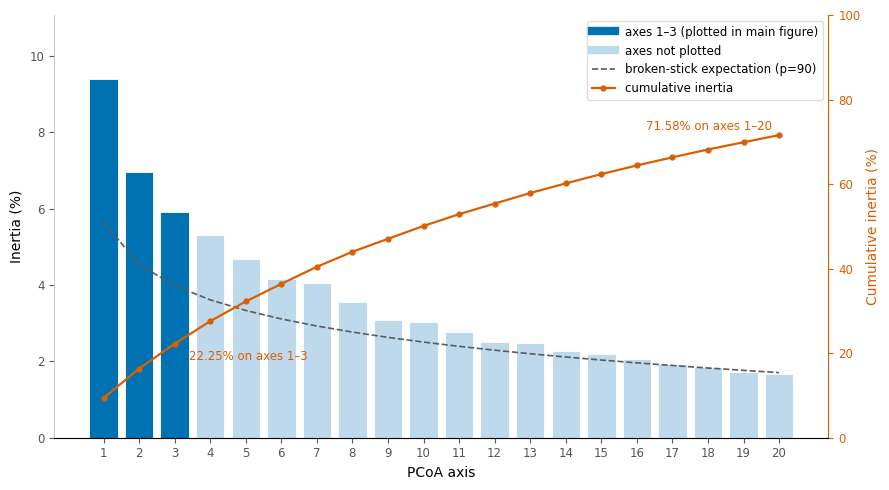

✓  PCoA_scree_18SSR.png / .svg

Axis  Eigenvalue  Inertia%  Cumulative%  Broken-stick%
   1     0.02370     9.38        9.38          5.65  *
   2     0.01762     6.97       16.35          4.54  *
   3     0.01491     5.90       22.25          3.98  *
   4     0.01341     5.31       27.56          3.61  *
   5     0.01181     4.68       32.24          3.33  *
   6     0.01048     4.15       36.39          3.11  *
   7     0.01024     4.05       40.44          2.93  *
   8     0.00898     3.55       43.99          2.77  *
   9     0.00775     3.07       47.06          2.63  *
  10     0.00769     3.04       50.10          2.50  *
  11     0.00701     2.78       52.88          2.39  *
  12     0.00634     2.51       55.39          2.29  *
  13     0.00630     2.49       57.88          2.20  *
  14     0.00576     2.28       60.16          2.11  *
  15     0.00555     2.20       62.36          2.03  *
  16     0.00518     2.05       64.41          1.96  *
  17     0.00486     1.92       6

In [ ]:
# ── CELL 8 ────────────────────────────────────────────────────────────────────
# Supplementary: scree + cumulative inertia for the DARwin PCoA (20 axes)
# Input : 94_sweet_cherry_18_SSR_T_square_root.AFT
# Note  : the square-root transform makes the matrix Euclidean, so ALL
#         eigenvalues are >= 0 and "number of positive axes" is not a stopping
#         rule. Broken stick is shown as a reference only; P_TOTAL must be the
#         full rank of the centred matrix (n_units - 1), not the 20 extracted.
# ──────────────────────────────────────────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

AFT_FILE = "94_sweet_cherry_18_SSR_T_square_root.AFT"
N_SHOWN  = 3          # axes plotted in the main PCoA figure

def read_inertia(path):
    with open(path, "r", encoding="cp1252", errors="replace") as f:
        lines = [l.rstrip("\n").rstrip("\r") for l in f]
    n_units = int(lines[1].split("\t")[0])
    i = next(k for k, l in enumerate(lines) if l.startswith("Axis\tEigenvalue"))
    ax, eig, pct = [], [], []
    for l in lines[i + 1:]:
        c = [x for x in l.split("\t") if x.strip() != ""]
        if len(c) < 3:
            break
        ax.append(int(c[0])); eig.append(float(c[1])); pct.append(float(c[2]))
    return n_units, np.array(ax), np.array(eig), np.array(pct)

n_units, ax, eig, pct = read_inertia(AFT_FILE)
P_TOTAL = n_units - 1                      # full rank of the Gower-centred matrix
cum = np.cumsum(pct)
total_inertia = eig[0] / (pct[0] / 100)    # back out the denominator DARwin used

print(f"{len(ax)} axes extracted of {P_TOTAL} possible | total inertia = {total_inertia:.4f}")
print(f"cumulative at axis {N_SHOWN}: {cum[N_SHOWN-1]:.2f}%   at axis {ax[-1]}: {cum[-1]:.2f}%")

# broken-stick expectation (% of total inertia) for axis k out of P_TOTAL
bs = np.array([100.0 / P_TOTAL * sum(1.0 / i for i in range(k, P_TOTAL + 1)) for k in ax])
above = pct > bs
print(f"axes exceeding broken stick (p={P_TOTAL}): "
      f"{int(above.sum())} of {len(ax)} extracted"
      f"{' — no cut-off reached within the extracted axes' if above.all() else ''}")

# ── figure ────────────────────────────────────────────────────────────────────
fig, a1 = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor("white"); a1.set_facecolor("white")

cols = ["#0072B2" if k <= N_SHOWN else "#BFD9EC" for k in ax]
a1.bar(ax, pct, color=cols, edgecolor="white", linewidth=0.6, zorder=3)
a1.plot(ax, bs, color="#5B5B5B", lw=1.2, ls="--", zorder=4)

a1.set_xlabel("PCoA axis", fontsize=10)
a1.set_ylabel("Inertia (%)", fontsize=10)
a1.set_xticks(ax)
a1.set_ylim(0, max(pct) * 1.18)
a1.tick_params(colors="#555555", labelsize=8.5)
for s in ("top", "right"):
    a1.spines[s].set_visible(False)
a1.spines["left"].set_color("#CCCCCC"); a1.spines["bottom"].set_color("#CCCCCC")

a2 = a1.twinx()
a2.plot(ax, cum, color="#D95F02", lw=1.6, marker="o", ms=3.5, zorder=5)
a2.set_ylabel("Cumulative inertia (%)", fontsize=10, color="#D95F02")
a2.set_ylim(0, 100)
a2.tick_params(axis="y", colors="#D95F02", labelsize=8.5)
a2.spines["top"].set_visible(False); a2.spines["left"].set_visible(False)
a2.spines["right"].set_color("#D95F02")

a2.annotate(f"{cum[N_SHOWN-1]:.2f}% on axes 1–{N_SHOWN}",
            (N_SHOWN, cum[N_SHOWN-1]), textcoords="offset points", xytext=(10, -12),
            fontsize=8.5, color="#D95F02")
a2.annotate(f"{cum[-1]:.2f}% on axes 1–{ax[-1]}",
            (ax[-1], cum[-1]), textcoords="offset points", xytext=(-96, 4),
            fontsize=8.5, color="#D95F02")

a1.legend(handles=[
    mlines.Line2D([], [], color="#0072B2", lw=6, label=f"axes 1–{N_SHOWN} (plotted in main figure)"),
    mlines.Line2D([], [], color="#BFD9EC", lw=6, label="axes not plotted"),
    mlines.Line2D([], [], color="#5B5B5B", lw=1.2, ls="--", label=f"broken-stick expectation (p={P_TOTAL})"),
    mlines.Line2D([], [], color="#D95F02", lw=1.6, marker="o", ms=3.5, label="cumulative inertia"),
], loc="upper right", fontsize=8.5, frameon=True, framealpha=0.95, edgecolor="#DDDDDD")

plt.tight_layout()
plt.savefig("PCoA_scree_18SSR.png", dpi=300, bbox_inches="tight")
plt.savefig("PCoA_scree_18SSR.svg", format="svg", bbox_inches="tight")
plt.show()
print("✓  PCoA_scree_18SSR.png / .svg")

print("\nAxis  Eigenvalue  Inertia%  Cumulative%  Broken-stick%")
for k, e, p, c, b in zip(ax, eig, pct, cum, bs):
    print(f"{k:>4}  {e:>10.5f}  {p:>7.2f}  {c:>10.2f}  {b:>12.2f}{'  *' if p > b else ''}")

# Pedigree drawing

##🍒Pedigree figure for UA sweet cherry SSR study

nodes 67   edges 75   ->  /content/Figure_pedigree.png  /content/Figure_pedigree.pdf


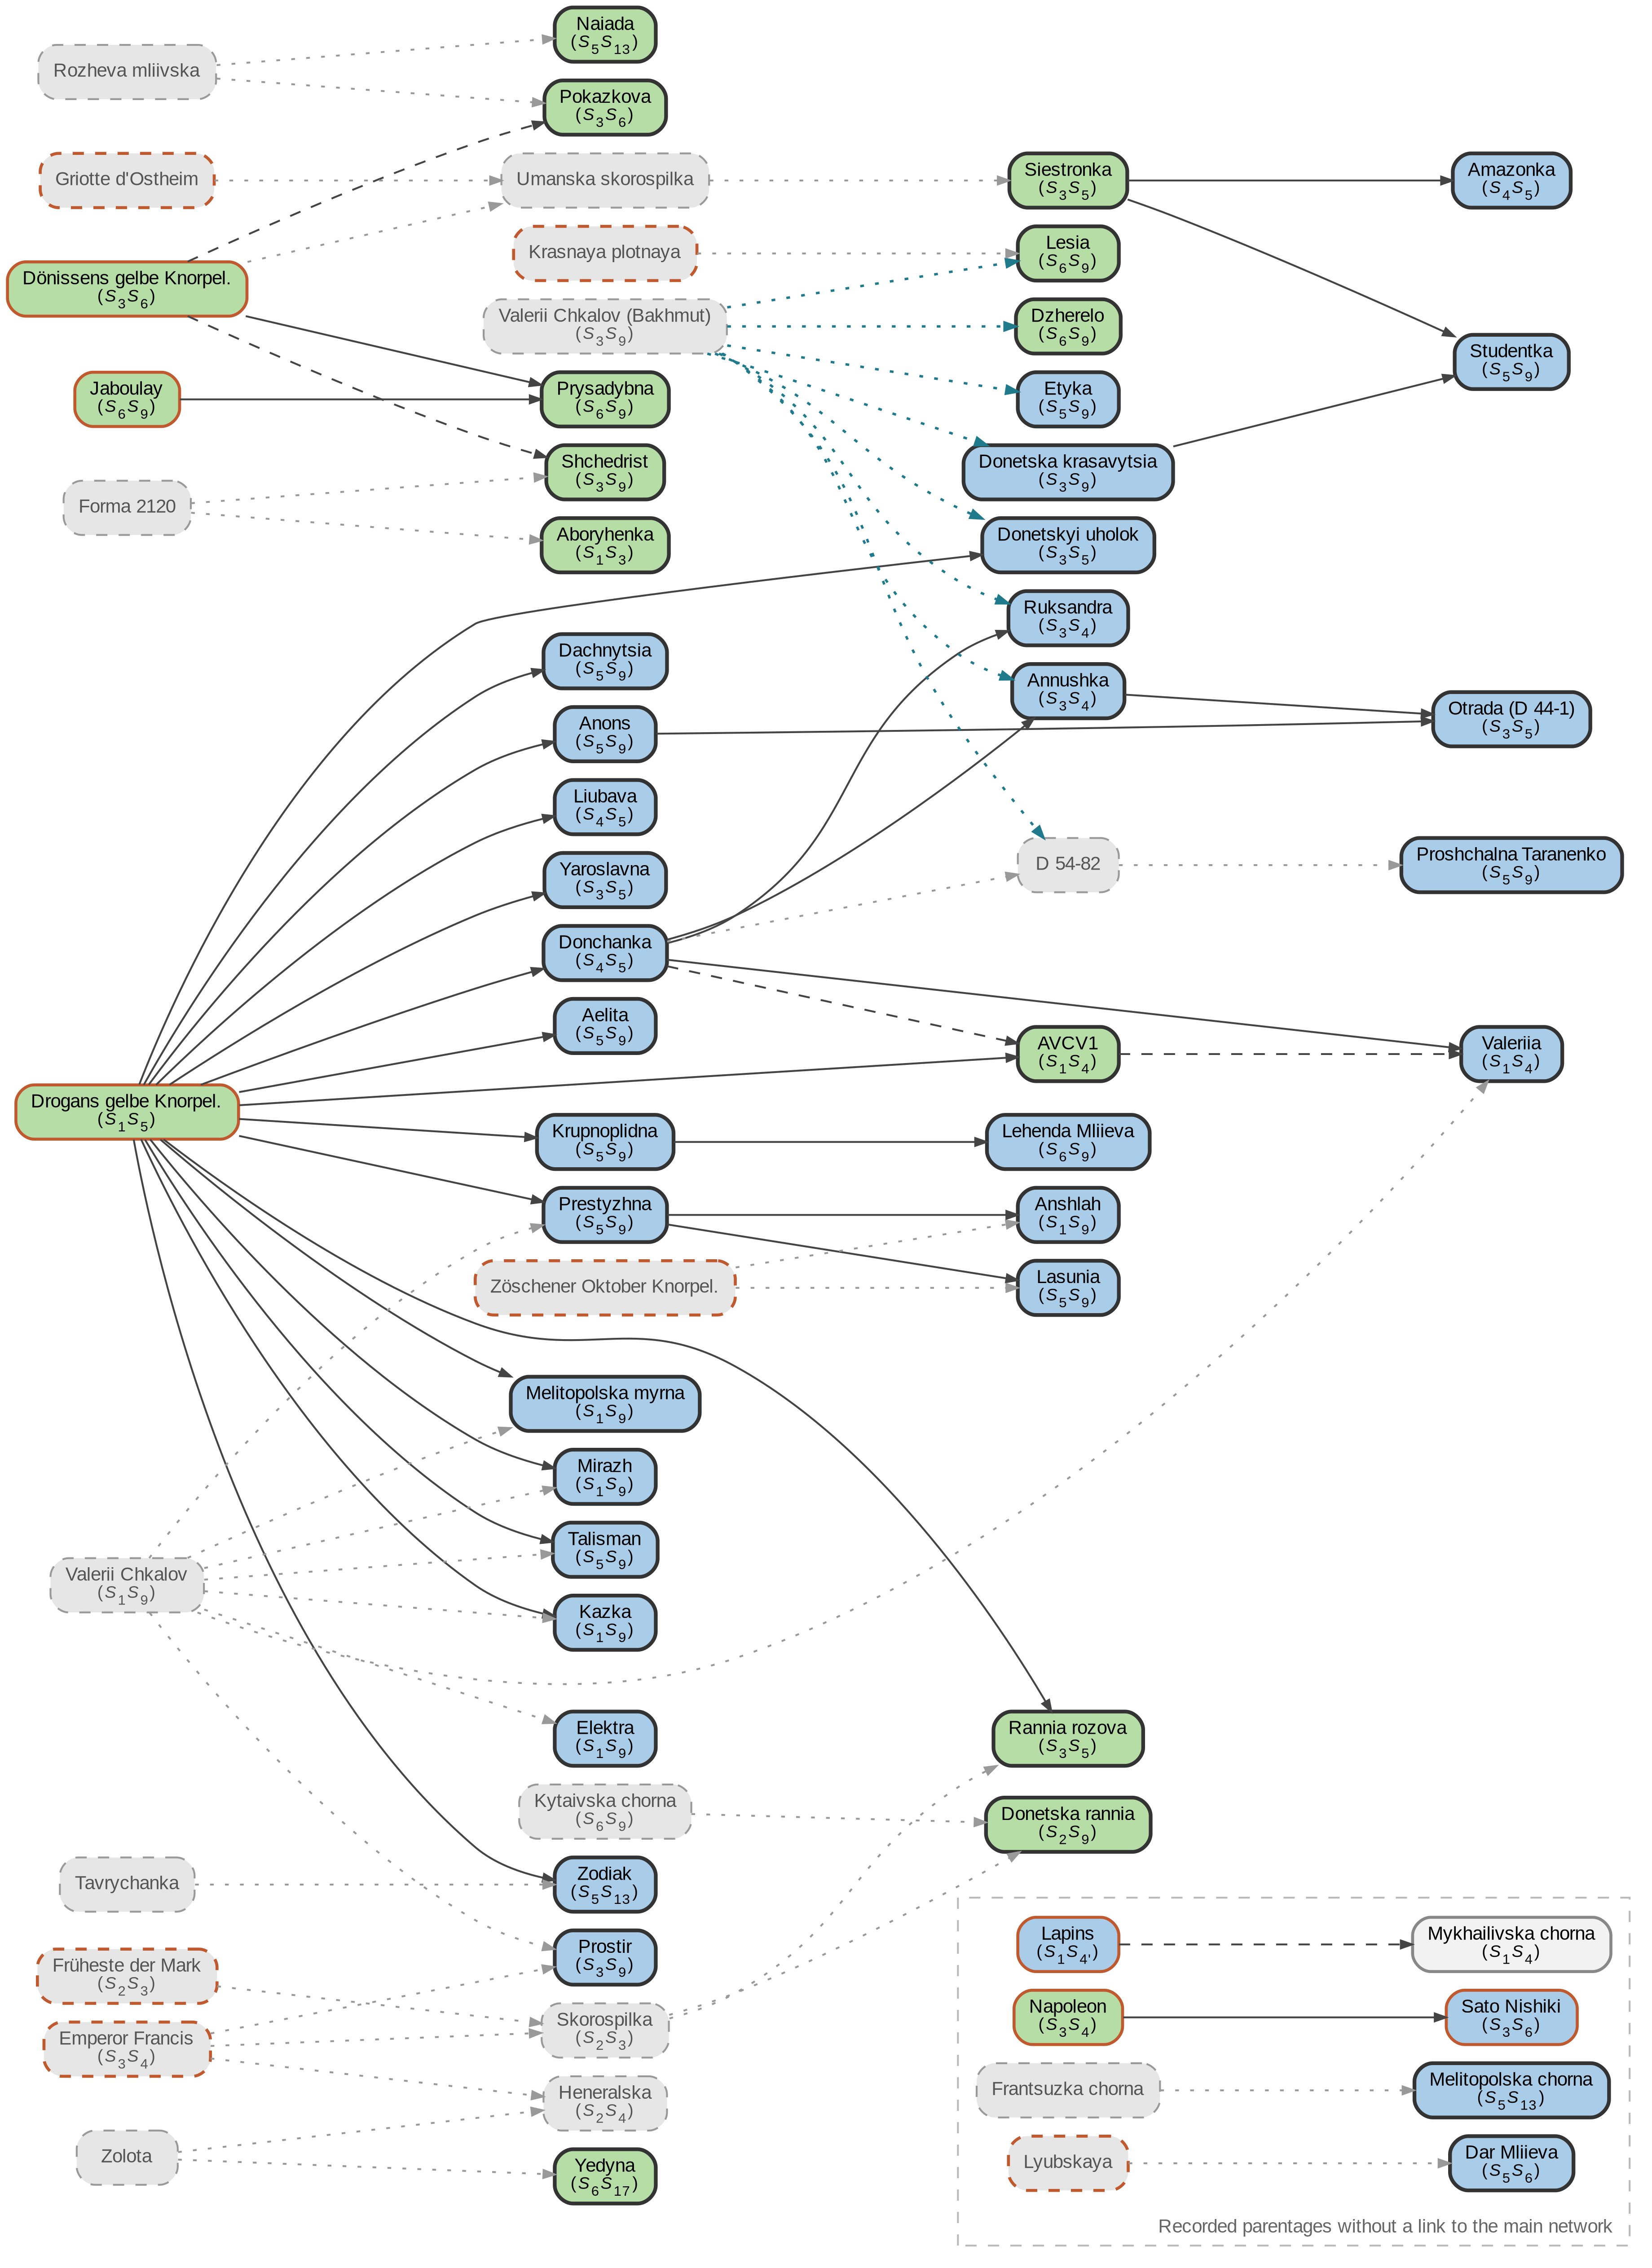

In [2]:
# ═══════════════════════════════════════════════════════════════════════════════
#  Pedigree figure — UA sweet cherry SSR study
#  edge  solid = confirmed · dashed = candidate · grey dotted = recorded, not genotyped
#        teal dotted = putative second 'Valerii Chkalov' (S3S9)
#  node  fill  = germplasm status · thick border = Ukrainian origin · grey = not genotyped
#  label cultivar name + S-genotype;  S italic, allele numbers upright subscript
# ═══════════════════════════════════════════════════════════════════════════════
import csv, re, html, unicodedata
from graphviz import Digraph

# ── ★ PATHS ───────────────────────────────────────────────────────────────────
PEDFILE  = "/content/pedigree_v2.csv"      # ID, Parent1, Parent2, P1_status, P2_status
METAFILE = "/content/metadata.csv"      # sample_name, status, origin, S_genotype
OUTSTEM  = "/content/Figure_pedigree"   # output basename (no extension)

# ── ★ SETTINGS ────────────────────────────────────────────────────────────────
FORMATS   = ("png", "pdf")   # NOTE the comma: ("png",) is a tuple, ("png") is a string
DPI       = 300              # PNG resolution; 200 ≈ 3100 px wide, 300 ≈ 4650 px
SHOW      = True             # draw the figure inline in the notebook
LIST_KEYS = False            # True -> print every node key, to pick ANCHOR from
ANCHOR    = "n_skorospilka"        # node the isolated-pairs box is anchored after

# ── ★ LAYOUT ──────────────────────────────────────────────────────────────────
RANKDIR = "LR"          # "LR" = founders left, progeny right (keeps the fan vertical)
FONT    = "Arial"
FILL    = {"Modern cultivar":          "#a9cce8",
           "Early selection cultivar": "#b6ddA6",
           "Landrace":                 "#f5d97e",
           "Wild":                     "#cfa9dd"}
NOGENO  = "#e6e6e6"     # recorded ancestor, not genotyped in this study
# ── ★ ALIASES  founder label in pedigree.csv -> sample_name in metadata ───────
ALIAS   = {"drogansgelbeknorpel": "110", "donissensgelbeknorpel": "DRO/1",
           "jaboulay": "108", "napoleon": "92", "lapins": "LAP"}
# published S-genotypes for ancestors not genotyped in this study (grey nodes)
ANCESTOR_S = {"valeriichkalov":   "S1/S9",   # expected/authentic
              "valeriichkalovbakhmut": "S3/S9",   # most-cited alternative (3 refs)
              "emperorfrancis":   "S3/S4",   # Schuster
              "skorospilka":      "S2/S3",   # Paprstein 2018; Patzak 2019
              "fruhestedermark":  "S2/S3",   # literature
              "heneralska":       "S2/S4",   # Schuster 2007, 2012, 2017
              "kytaivskachorna":  "S6/S9"}   # from KYT/4 and KYT/6
# grey ancestors of non-Ukrainian origin -> orange rim on the grey fill
FOREIGN = {"emperorfrancis", "fruhestedermark", "zoscheneroktoberknorpel",
           "griottedostheim", "lyubskaya", "krasnayaplotnaya"}
# ──────────────────────────────────────────────────────────────────────────────
# keys above may be written with or without the n_/c_ node-id prefix — accept both
_strip = lambda k: re.sub(r"^[nc]_", "", k)
ANCESTOR_S = {_strip(k): v for k, v in ANCESTOR_S.items()}
FOREIGN    = {_strip(k) for k in FOREIGN}

def read_table(path):
    for enc in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            with open(path, encoding=enc) as fh:
                head = fh.read(4096); fh.seek(0)
                delim = "\t" if head.count("\t") > head.count(",") else ","
                return list(csv.DictReader(fh, delimiter=delim))
        except UnicodeDecodeError:
            continue
    raise UnicodeDecodeError(f"cannot decode {path}")

def norm(s):
    s = unicodedata.normalize("NFKD", s or "").lower()
    s = re.sub(r"\[[^\]]*\]", "", s)
    return re.sub(r"[^a-z0-9]+", "", s)

def code_of(s):                                   # "Aelita [AEL/1]" -> "AEL/1"
    m = re.search(r"\[([^\]]+)\]\s*$", s or "")
    return m.group(1).strip() if m else ""

def plain(s):                                     # drop the trailing sample code
    return re.sub(r"\s*\[[^\]]*\]\s*$", "", s or "").strip()

def slabel(sgen):                                 # "S5/S9" -> (S5S9) markup
    nums = re.findall(r"S\s*([\w']+)", sgen or "", re.I)   # was \w+
    if not nums:
        return ""
    inner = "".join(f"<I>S</I><SUB>{html.escape(n)}</SUB>" for n in nums)
    return f"<BR/><FONT POINT-SIZE='9'>({inner})</FONT>"

rows = read_table(PEDFILE)
meta = {}
try:
    for r in read_table(METAFILE):
        k = (r.get("sample_name") or r.get("ID") or "").strip()
        if k:
            meta[k] = r
except FileNotFoundError:
    print("metadata not found — nodes unstyled")

# ── keys: trailing [CODE] is unique; parents are matched on display name -------
def key_of(raw):                                  # DOT ids must be free of ':' (port sep)
    c = code_of(raw)
    return ("c_" + re.sub(r"[^A-Za-z0-9]+", "_", c)) if c else ("n_" + norm(raw))

label_of, name_index = {}, {}
for r in rows:                                    # offspring first — they own the code
    k = key_of(r["ID"])
    label_of[k] = r["ID"].strip()
    name_index.setdefault(norm(plain(r["ID"])), k)

def parent_key(p):                                # resolve a parent written by name
    return name_index.get(norm(p)) or ("n_" + norm(p))

for r in rows:                                    # parents never listed as offspring
    for p in (r["Parent1"], r["Parent2"]):
        if p.strip():
            label_of.setdefault(parent_key(p), p.strip())

def meta_for(raw):
    return meta.get(code_of(raw)) or meta.get(ALIAS.get(norm(raw), "\0")) or {}

g = Digraph("pedigree")
g.attr(rankdir=RANKDIR, splines="spline", nodesep="0.14", ranksep="1.7",
       bgcolor="white", concentrate="true", dpi=str(DPI))
g.attr("node", shape="box", style="rounded,filled", fontname=FONT,
       fontsize="10", height="0.40", margin="0.11,0.06")
g.attr("edge", arrowsize="0.6")

for k, raw in label_of.items():
    m = meta_for(raw)
    name = html.escape(plain(raw))
    if m:
        fill = FILL.get((m.get("status") or "").strip(), "#f2f2f2")
        org  = (m.get("origin") or "").strip()
        ukr  = org.lower().startswith(("ukr", "україн"))
        unk  = org.upper() in ("", "NA", "N/A", "UNKNOWN")
        g.node(k, f"<{name}{slabel(m.get('S_genotype'))}>", fillcolor=fill,
               color="#333333" if ukr else ("#888888" if unk else "#c05a2e"),
               penwidth="2" if ukr else "1.6")
    else:                                         # recorded ancestor, never genotyped
        foreign = norm(raw) in FOREIGN
        g.node(k, f"<{name}{slabel(ANCESTOR_S.get(norm(raw), ''))}>",
               fillcolor=NOGENO, color="#c05a2e" if foreign else "#999999",
               penwidth="1.6" if foreign else "1",
               style="rounded,filled,dashed", fontcolor="#555555")

STYLE = {"candidate":   dict(style="dashed", color="#444444"),
         "recorded":    dict(style="dotted", color="#999999"),
         "recorded_v2": dict(style="dotted", color="#1f7a8c", penwidth="1.3")}
n_edges = 0
for r in rows:
    for p, st in ((r["Parent1"], r["P1_status"]), (r["Parent2"], r["P2_status"])):
        if not p.strip():
            continue
        g.edge(parent_key(p), key_of(r["ID"]),
               **STYLE.get((st or "").strip().lower(),
                           dict(style="solid", color="#444444")))
        n_edges += 1

# ── isolated pairs: box them so they read as an appendix, not as lost nodes ───
adj = {}
for r in rows:
    a = key_of(r["ID"])
    for p in (r["Parent1"], r["Parent2"]):
        if p.strip():
            b = parent_key(p)
            adj.setdefault(a, set()).add(b); adj.setdefault(b, set()).add(a)
seen, comps = set(), []
for nd in adj:
    if nd in seen: continue
    st, c = [nd], set()
    while st:
        x = st.pop()
        if x in c: continue
        c.add(x); st += [y for y in adj[x] if y not in c]
    seen |= c; comps.append(c)

small = [c for c in comps if len(c) <= 3]
if small:
    pairs = []                                    # order each pair as (parent, child)
    for c in small:
        par = {parent_key(p) for r in rows for p in (r["Parent1"], r["Parent2"])
               if p.strip() and parent_key(p) in c}
        src = sorted(par) or sorted(c)[:1]
        dst = sorted(c - set(src))
        pairs.append((src[0], dst[0] if dst else src[0]))

    with g.subgraph(name="cluster_iso") as sub:
        sub.attr(label="Recorded parentages without a link to the main network",
                 labelloc="b", labeljust="r", fontname=FONT, fontsize="10",
                 fontcolor="#666666", color="#bbbbbb", style="dashed", margin="10")
        with sub.subgraph() as col1:               # all parents on one rank
            col1.attr(rank="same")
            for a, _ in pairs: col1.node(a)
        with sub.subgraph() as col2:               # all offspring on the next
            col2.attr(rank="same")
            for _, b in pairs: col2.node(b)

    if ANCHOR in label_of:                         # push the whole box to the right
        for a, _ in pairs:
            g.edge(ANCHOR, a, style="invis", weight="0")

for fmt in FORMATS:
    with open(f"{OUTSTEM}.{fmt}", "wb") as fh:
        fh.write(g.pipe(format=fmt))
print(f"nodes {len(label_of)}   edges {n_edges}   ->  " +
      "  ".join(f"{OUTSTEM}.{f}" for f in FORMATS))

if LIST_KEYS:
    print("\nnode keys (use one as ANCHOR):")
    for k in sorted(label_of):
        print(f"   {k:<28} {label_of[k]}")

if SHOW:                                  # PNG preview: scales better than SVG in Colab
    try:
        from IPython.display import Image as _Img, display as _show
        png = f"{OUTSTEM}.png"
        if "png" not in FORMATS:
            png = f"{OUTSTEM}._preview.png"
            open(png, "wb").write(g.pipe(format="png"))
        _show(_Img(filename=png))
    except ImportError:
        pass